# Session 10 - Sequence Classification, Tagging, Fine-tuning, and LoRA

This notebook turns the session into a guided learning path:

```text
Theory -> Tensor shapes -> Code -> Prediction inspection -> Practical trade-off
```

We start with simple recurrent models so the mechanics are visible, then move to pretrained transformer tooling and parameter-efficient fine-tuning.


## Notebook Map

| Part | Topic | Main question |
|---|---|---|
| A | From-scratch sequence classification | How do we map one sequence to one label? |
| B | From-scratch sequence tagging | How do we predict one label per token? |
| C | Transformer tokenization | Why do subwords change the data pipeline? |
| D | Full fine-tuning | How do pretrained encoders become task models? |
| E | PEFT and LoRA | How can we train fewer parameters? |
| F | Comparison and recap | What trade-offs should we remember? |

---


## How to use this notebook

- **Run it top to bottom.** Cells build on variables defined earlier (the vocab, the models, the tokenizers), so a fresh "Restart & Run All" is the safe way to run it.
- **You need a GPU** for the transformer sections (Parts C-F) to finish quickly, and **internet on the first run** (to download the datasets, the DistilBERT checkpoints, and the metric scripts). After that everything is cached.
- **Runtime:** roughly 5-10 minutes end to end on a single modern GPU; the from-scratch parts (A-B) also run fine on CPU.
- **The outputs are already filled in** so you can read it like an article - but exact numbers will drift a little when you re-run (training is not perfectly deterministic).
- **Look for the call-out boxes:** *Theory Card* (concept), *Debug checkpoint* / *In practice* (what matters in real work), *Intuition Check* (test yourself), and **Your turn** (small hands-on exercises).


> **Visual compatibility note:** diagrams in this notebook are generated SVG files in `ps-session/assets/` and embedded with standard Markdown image links. This avoids custom HTML/CSS rendering differences across notebook viewers.


![Session learning arc](assets/session_learning_arc.svg)


> ## Theory Card - Sequence Classification
>
> Sequence classification maps an entire input sequence to one label.
>
> Examples:
>
> - Movie review -> positive / negative
> - Email -> spam / not spam
> - Customer message -> billing / technical / refund
>
> The model must compress the full sequence into a single representation.


![Sequence classification pipeline](assets/sequence_classification.svg)


> ## Theory Card - Embeddings
>
> A token ID is only a categorical lookup key. The number `42` is not "twice as meaningful" as token ID `21`.
>
> An embedding layer learns a dense vector for each token ID. During training, tokens used in similar contexts can move toward similar regions of embedding space.
>
> **Key idea:** token IDs become useful only after the embedding lookup.


In [1]:
# If a package is missing, install it in your notebook environment before running the rest:
# pip install torch datasets transformers evaluate peft seqeval scikit-learn matplotlib pandas
#
# Note: datasets>=4 removed support for script-based datasets, so this notebook loads
# CoNLL-2003 from the parquet mirror "tomaarsen/conll2003" (identical schema) in Part B.

import inspect
import math
import random
import re
import time
from collections import Counter

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score, f1_score as sklearn_f1_score
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


  from .autonotebook import tqdm as notebook_tqdm


device(type='cuda')

In [2]:
# A few small helpers reused throughout the notebook.

def count_trainable_parameters(model):
    # Sum the size of every parameter tensor that still receives gradients.
    # For LoRA this is tiny; for full fine-tuning it is the whole network.
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def count_total_parameters(model):
    # Every parameter, frozen or not - lets us report the trainable fraction.
    return sum(p.numel() for p in model.parameters())


def simple_tokenize(text):
    # A deliberately crude word tokenizer for the from-scratch models: lowercase,
    # then grab word-ish runs (with internal apostrophes like "don't"), standalone
    # numbers, or single punctuation marks. No subwords yet - that arrives in Part C.
    pattern = r"[A-Za-z]+(?:'[A-Za-z]+)?|[0-9]+|[^\sA-Za-z0-9]"
    return re.findall(pattern, text.lower())


def show_history_curves(history, title_prefix=""):
    # Plot the per-epoch training history twice: loss curves, then score curves.
    # Reading these two plots together is how we spot under/over-fitting.
    if not history:
        print("No history to plot yet.")
        return

    history_df = pd.DataFrame(history)   # list of per-epoch dicts -> tidy table

    # Plot 1: training vs validation loss. A growing gap = overfitting.
    plt.figure(figsize=(7, 4))
    plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="train loss")
    plt.plot(history_df["epoch"], history_df["loss"], marker="o", label="validation loss")
    plt.title(f"{title_prefix}Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

    # Plot 2: the validation metrics we actually care about (accuracy / F1),
    # only drawn if the history rows contain them.
    metric_cols = [col for col in ["accuracy", "f1"] if col in history_df.columns]
    if metric_cols:
        plt.figure(figsize=(7, 4))
        for col in metric_cols:
            plt.plot(history_df["epoch"], history_df[col], marker="o", label=col)
        plt.title(f"{title_prefix}Validation Metrics")
        plt.xlabel("Epoch")
        plt.ylabel("Score")
        plt.legend()
        plt.show()


## Training Configuration - the dials a researcher actually turns

In a real project these are not "set once and forget" constants. They are the knobs you *sweep*: change one, rerun, read the validation curve, repeat. We gather them in one place so that **every model in this notebook trains under the same honest, comparable budget** instead of magic numbers scattered across cells.

Two ideas make the later scratch-vs-transformer comparison fair:

- **A shared epoch budget.** Every model may train for up to `EPOCHS` passes - not 3 for one model and 1 for another.
- **Early stopping.** Training ends as soon as the validation metric stops improving, so nothing is accidentally under- or over-trained. This is closer to what people actually do than picking an epoch count by hand.

> **What a researcher iterates over:** the **learning rate** (usually the single highest-impact knob), the number of **epochs**, **batch size**, model **width/depth**, **dropout** / weight decay, and the **train/validation split**. You rarely get these right on the first try - you run, look at the curves, and adjust.


In [ ]:
# Each model trains for AT MOST `EPOCHS` passes, but early stopping (see the
# train_*_model loops and the Hugging Face EarlyStoppingCallback) cuts training
# short once the validation metric plateaus. Same budget + same stopping rule
# for every model is what makes the Part F comparison fair rather than rigged.
EPOCHS = 5          # upper bound on passes over the training data
PATIENCE = 2        # stop if val metric does not improve for this many evaluations

SCRATCH_LR = 1e-3   # Adam LR for the from-scratch LSTMs (trained from random init)
HF_LR = 2e-5        # full fine-tuning LR - deliberately SMALL: nudge pretrained weights gently
LORA_LR = 5e-4      # LoRA tolerates a larger LR: it trains a few freshly-initialised params

# Subset sizes keep the live session fast. Bigger is better and slower; in
# production you would use the full dataset (with more epochs + early stopping).
CLS_TRAIN_SIZE = 4000       # SST-2 examples for the FIRST (deliberately under-regularised) scratch run
CLS_FIX_TRAIN_SIZE = 12000   # bigger set for the regularised "fix" run later in Part A
NER_TRAIN_SIZE = 5000       # CoNLL training sentences for the scratch tagger
HF_TRAIN_SIZE = 8000        # transformer training examples (matched to the scratch fix-run for a fair Part F)

print(f"EPOCHS={EPOCHS}  PATIENCE={PATIENCE}  device={device}")


EPOCHS=5  PATIENCE=2  device=cuda


# Part A - From-scratch Sequence Classification

> **Key idea:** build the smallest useful neural text classifier before introducing pretrained tooling.


In [4]:
# SST-2 (Stanford Sentiment Treebank): single sentences labelled positive / negative.
raw_cls = load_dataset("glue", "sst2")

# We shuffle first (the raw file is ordered) and take a fixed subset for speed.
# `seed=SEED` makes the subset reproducible - rerunning gives the same examples.
train_cls = raw_cls["train"].shuffle(seed=SEED).select(range(CLS_TRAIN_SIZE))
valid_cls = raw_cls["validation"].select(range(872))   # full SST-2 dev set

# Always eyeball a few raw rows before modelling - it catches schema surprises early.
pd.DataFrame(train_cls[:5])


,sentence,label,idx
0,"klein , charming in comedies like american pie...",1,32326
1,be fruitful,1,27449
2,soulful and,1,60108
3,the proud warrior that still lingers in the so...,1,23141
4,covered earlier and much better,0,35226


## Dataset Label Distribution

A balanced dataset makes accuracy easier to interpret. If one class dominates, accuracy can be misleading.


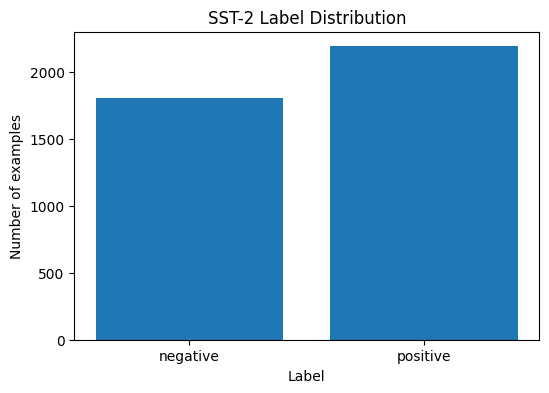

In [5]:
# Count how many examples carry each label (0/1), sorted so 0 comes first.
label_counts = pd.Series(train_cls["label"]).value_counts().sort_index()
label_counts.index = ["negative", "positive"]   # rename 0/1 to readable labels

# A quick bar chart. If the two bars are roughly equal the classes are balanced,
# which means plain accuracy is a trustworthy metric (no majority class to game).
plt.figure(figsize=(6, 4))
plt.bar(label_counts.index, label_counts.values)
plt.title("SST-2 Label Distribution")
plt.xlabel("Label")
plt.ylabel("Number of examples")
plt.show()


## Sentence Length Distribution

Length distribution helps us choose `max_len`.

If `max_len` is too small, we truncate useful information. If it is too large, we waste memory on padding.


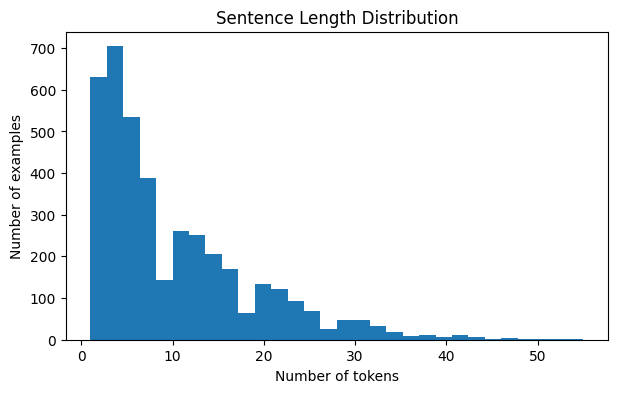

count    4000.000000
mean       10.027500
std         8.623708
min         1.000000
25%         3.000000
50%         7.000000
75%        14.000000
max        55.000000
dtype: float64

In [6]:
# Tokenize every training sentence and record its length (in tokens).
lengths = [len(simple_tokenize(x)) for x in train_cls["sentence"]]

# The histogram shows where most sentences fall. We use it to pick `max_len`:
# long enough to keep almost every sentence whole, short enough to avoid padding waste.
plt.figure(figsize=(7, 4))
plt.hist(lengths, bins=30)
plt.title("Sentence Length Distribution")
plt.xlabel("Number of tokens")
plt.ylabel("Number of examples")
plt.show()

pd.Series(lengths).describe()   # min/max/mean/quartiles - the numbers behind the plot


> ## Theory Card - Padding and Masking
>
> Batches need rectangular tensors, but sentences have different lengths.
>
> Padding adds dummy tokens so every example in a batch has the same length. Masking tells the model or loss function which positions are real and which are padding.
>
> **Practical warning:** padding tokens should not contribute to a tagging loss, and embedding layers should use `padding_idx`.


In [7]:
# Two reserved tokens with FIXED ids that every model relies on:
PAD_TOKEN = "<pad>"   # filler for short sentences in a batch
UNK_TOKEN = "<unk>"   # stand-in for any word not in the vocabulary (out-of-vocab)
PAD_ID = 0            # id 0 is padding everywhere (and the embedding's padding_idx)
UNK_ID = 1            # id 1 is the unknown-word bucket


def build_vocab(texts, min_freq=2, max_size=20000):
    # Build a word -> integer-id mapping from the training text.
    counts = Counter()
    for text in texts:
        counts.update(simple_tokenize(text))   # tally every token's frequency

    # Start with the reserved tokens so PAD_ID/UNK_ID keep their fixed slots, then
    # add the most frequent words. min_freq drops rare words (they would just be
    # noise / overfit), and max_size caps the embedding table size.
    vocab = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}
    for token, freq in counts.most_common(max_size - len(vocab)):
        if freq < min_freq:
            break                # most_common is sorted, so once we hit a rare word we can stop
        vocab[token] = len(vocab)   # assign the next free id
    return vocab


# Build the classifier vocabulary from the training sentences only (never the
# validation set - that would leak information). Inspect its size and first entries.
vocab = build_vocab(train_cls["sentence"], min_freq=2, max_size=12000)
len(vocab), list(vocab.items())[:10]


(3311,
 [('<pad>', 0),
  ('<unk>', 1),
  ('the', 2),
  (',', 3),
  ('a', 4),
  ('and', 5),
  ('-', 6),
  ('.', 7),
  ('of', 8),
  ("'", 9)])

> ## Theory Card - RNN Intuition
>
> A recurrent neural network reads a sequence one step at a time. At each token, it combines the current token representation with a memory vector from the previous step.
>
> This creates a chain of hidden states:
>
> ```text
> x1 -> h1 -> h2 -> h3 -> ... -> hT
> ```
>
> For classification, the final hidden state is often used as a compact representation of the full sequence.


> ## Theory Card - LSTM Gating Intuition
>
> A plain RNN can struggle to remember information over long distances.
>
> An LSTM adds gates that learn what to keep, what to forget, and what to expose as the hidden state. You can think of the cell state as a longer-term memory path controlled by learned switches.
>
> **Interview-style question:** why might a model need both short-term hidden state and longer-term cell state?


> ## Theory Card - Bidirectionality
>
> A left-to-right LSTM sees only previous context. A bidirectional LSTM reads the sentence in both directions and concatenates both views.
>
> This is especially helpful when later words clarify earlier words.


In [8]:
# A torch Dataset turns one raw example into model-ready tensors. It must define
# __len__ (how many examples) and __getitem__ (return example i).
class SST2Dataset(Dataset):
    def __init__(self, split, vocab, max_len=64):
        self.split = split        # a Hugging Face dataset split
        self.vocab = vocab        # word -> id mapping built above
        self.max_len = max_len    # hard cap on tokens per sentence (truncation)

    def __len__(self):
        return len(self.split)

    def __getitem__(self, idx):
        item = self.split[idx]
        # Tokenize and truncate to at most max_len tokens.
        tokens = simple_tokenize(item["sentence"])[: self.max_len]
        if not tokens:                 # guard against empty strings
            tokens = [UNK_TOKEN]
        # Map each token to its id; unknown words fall back to UNK_ID.
        input_ids = [self.vocab.get(token, UNK_ID) for token in tokens]
        return {
            "input_ids": torch.tensor(input_ids, dtype=torch.long),   # variable length here
            "label": torch.tensor(item["label"], dtype=torch.long),
            "text": item["sentence"],                                 # kept for inspection
        }


# A collate_fn stitches a list of per-example dicts into ONE padded batch tensor.
# The DataLoader calls it once per batch; this is where ragged sentences become a
# rectangular (batch, time) tensor.
def collate_cls(batch):
    # True length of each sentence, before padding (needed later for packing).
    lengths = torch.tensor([len(item["input_ids"]) for item in batch], dtype=torch.long)
    max_len = int(lengths.max().item())          # pad up to the longest in THIS batch
    # Start from an all-PAD tensor, then drop each sentence into its row.
    input_ids = torch.full((len(batch), max_len), PAD_ID, dtype=torch.long)
    labels = torch.stack([item["label"] for item in batch])
    texts = [item["text"] for item in batch]

    for i, item in enumerate(batch):
        ids = item["input_ids"]
        input_ids[i, : len(ids)] = ids           # left-aligned; the rest stays PAD_ID

    # Mask is True at real tokens, False at padding - lets the model ignore pads.
    attention_mask = input_ids.ne(PAD_ID)
    return {
        "input_ids": input_ids,
        "lengths": lengths,
        "attention_mask": attention_mask,
        "labels": labels,
        "texts": texts,
    }


max_len_cls = 64   # chosen from the length histogram above - covers ~all sentences
train_cls_ds = SST2Dataset(train_cls, vocab, max_len=max_len_cls)
valid_cls_ds = SST2Dataset(valid_cls, vocab, max_len=max_len_cls)

# shuffle=True for training (break order-correlations), False for eval (reproducible).
train_cls_loader = DataLoader(train_cls_ds, batch_size=64, shuffle=True, collate_fn=collate_cls)
valid_cls_loader = DataLoader(valid_cls_ds, batch_size=128, shuffle=False, collate_fn=collate_cls)

# Pull one batch to confirm the shapes: input_ids is (B, T), lengths/labels are (B,).
batch = next(iter(train_cls_loader))
batch["input_ids"].shape, batch["lengths"].shape, batch["labels"].shape


(torch.Size([64, 46]), torch.Size([64]), torch.Size([64]))

## Tensor Shape Walkthrough - Sequence Classification

For batch size `B`, sequence length `T`, embedding dimension `E`, hidden size `H`, and class count `C`:

| Object | Shape | Meaning |
|---|---:|---|
| `input_ids` | `(B, T)` | token IDs |
| `embedded` | `(B, T, E)` | token vectors |
| `lstm_outputs` | `(B, T, 2H)` | contextual token vectors for a BiLSTM |
| `final_hidden` | `(B, 2H)` | sentence representation |
| `logits` | `(B, C)` | class scores |


## Implementation Blueprint - LSTM Classifier as Pieces

Before reading the full `nn.Module`, inspect the architecture as three separate parts.

![LSTM classifier blueprint](assets/classifier_blueprint.svg)


In [9]:
# Architecture preview: the same three pieces the class wraps, run by hand once
# with tiny dimensions (E=8, H=16) so each shape is easy to read.
preview_embedding = nn.Embedding(len(vocab), 8, padding_idx=PAD_ID)       # ids -> 8-d vectors
preview_encoder = nn.LSTM(8, 16, batch_first=True, bidirectional=True)    # BiLSTM, hidden=16/direction
preview_head = nn.Linear(32, 2)                                          # 32 = 2 directions x 16 -> 2 classes

preview_ids = batch["input_ids"][:4]        # take 4 sentences from the batch above
preview_lengths = batch["lengths"][:4]

preview_embedded = preview_embedding(preview_ids)            # (4, T) -> (4, T, 8)
# Pack so the LSTM skips padding and the final state is taken at the true last token.
preview_packed = pack_padded_sequence(
    preview_embedded,
    preview_lengths,
    batch_first=True,
    enforce_sorted=False,
)
# h_n holds the last hidden state per direction; [-2]=forward, [-1]=backward.
_, (preview_h_n, _) = preview_encoder(preview_packed)
preview_sentence_vector = torch.cat([preview_h_n[-2], preview_h_n[-1]], dim=1)   # (4, 32)
preview_logits = preview_head(preview_sentence_vector)                           # (4, 2)

# Tabulate how the shape shrinks from a sequence of ids to one score-pair per sentence.
pd.DataFrame([
    {"stage": "input IDs", "shape": tuple(preview_ids.shape), "meaning": "token IDs"},
    {"stage": "embedding", "shape": tuple(preview_embedded.shape), "meaning": "token vectors"},
    {"stage": "sentence vector", "shape": tuple(preview_sentence_vector.shape), "meaning": "compressed sequence"},
    {"stage": "logits", "shape": tuple(preview_logits.shape), "meaning": "class scores"},
])


,stage,shape,meaning
0,input IDs,"(4, 46)",token IDs
1,embedding,"(4, 46, 8)",token vectors
2,sentence vector,"(4, 32)",compressed sequence
3,logits,"(4, 2)",class scores


In [10]:
class LSTMTextClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_size=128,
        num_classes=2,
        bidirectional=True,
        padding_idx=PAD_ID,
        dropout=0.2,
    ):
        super().__init__()
        self.bidirectional = bidirectional
        # Embedding: lookup table (vocab_size x embedding_dim). padding_idx ties the
        # PAD row to zeros and freezes its gradient, so padding contributes nothing.
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=padding_idx)
        # The recurrent encoder. batch_first=True means tensors are (batch, time, features).
        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_size,
            batch_first=True,
            bidirectional=bidirectional,
        )
        # A BiLSTM outputs 2*hidden_size (forward+backward concatenated).
        hidden_factor = 2 if bidirectional else 1
        self.dropout = nn.Dropout(dropout)            # regularisation before the head
        # The classification head: sentence vector -> one score per class.
        self.classifier = nn.Linear(hidden_size * hidden_factor, num_classes)

    def forward(self, input_ids, lengths=None, return_shapes=False):
        embedded = self.embedding(input_ids)            # (B, T) ids -> (B, T, E) vectors

        if lengths is not None:
            # Packing tells the LSTM the true length of each row so it never wastes
            # computation on padding and the hidden state is taken at the LAST REAL
            # token, not at a pad. enforce_sorted=False lets rows arrive unsorted.
            packed = pack_padded_sequence(
                embedded,
                lengths.cpu(),
                batch_first=True,
                enforce_sorted=False,
            )
            packed_outputs, (h_n, c_n) = self.lstm(packed)
            lstm_outputs, _ = pad_packed_sequence(packed_outputs, batch_first=True)
        else:
            lstm_outputs, (h_n, c_n) = self.lstm(embedded)

        # h_n holds the final hidden state per direction. For a BiLSTM we concatenate
        # the forward pass's last state (h_n[-2]) with the backward pass's (h_n[-1])
        # to get one sentence vector that has seen the whole sequence both ways.
        if self.bidirectional:
            final_hidden = torch.cat([h_n[-2], h_n[-1]], dim=1)
        else:
            final_hidden = h_n[-1]

        logits = self.classifier(self.dropout(final_hidden))   # (B, 2H) -> (B, num_classes)

        if return_shapes:
            return logits, {
                "input_ids": tuple(input_ids.shape),
                "embedded": tuple(embedded.shape),
                "lstm_outputs": tuple(lstm_outputs.shape),
                "final_hidden": tuple(final_hidden.shape),
                "logits": tuple(logits.shape),
            }
        return logits


# Instantiate the real classifier and move it onto the GPU/CPU (`device`).
model_cls = LSTMTextClassifier(vocab_size=len(vocab), bidirectional=True).to(device)
print("trainable params:", count_trainable_parameters(model_cls))

# A single forward pass with no_grad (no gradients = faster, less memory) just to
# print the shape at every stage and confirm the wiring matches the table above.
with torch.no_grad():
    logits, shapes = model_cls(
        batch["input_ids"].to(device),
        batch["lengths"].to(device),
        return_shapes=True,
    )

for name, shape in shapes.items():
    print(f"{name}: {shape}")


trainable params: 688514
input_ids: (64, 46)
embedded: (64, 46, 128)
lstm_outputs: (64, 46, 256)
final_hidden: (64, 256)
logits: (64, 2)


## Training Loop Microscope - One Classification Batch

Before the full training function, watch one batch move through the learning loop.

![One-batch classification training loop](assets/classification_training_loop.svg)


In [11]:
# A tiny one-batch training step on a throwaway model, so the four moves of EVERY
# training loop are visible in isolation (the real loop below just repeats them).
demo_cls_model = LSTMTextClassifier(vocab_size=len(vocab), bidirectional=True).to(device)
demo_optimizer = torch.optim.Adam(demo_cls_model.parameters(), lr=1e-3)   # the weight updater
demo_criterion = nn.CrossEntropyLoss()                                    # the loss for classification

demo_input_ids = batch["input_ids"].to(device)
demo_lengths = batch["lengths"].to(device)
demo_labels = batch["labels"].to(device)

demo_optimizer.zero_grad()                              # 1. clear gradients from the previous step
demo_logits = demo_cls_model(demo_input_ids, demo_lengths)   # 2. FORWARD: inputs -> class scores
demo_loss = demo_criterion(demo_logits, demo_labels)   #    measure how wrong we are
demo_loss.backward()                                   # 3. BACKWARD: fill .grad for every parameter

# Peek at the gradient magnitude flowing into the classifier (a health check:
# ~0 means nothing is learning, huge means it may diverge).
grad_norm = demo_cls_model.classifier.weight.grad.norm().item()
demo_optimizer.step()                                  # 4. UPDATE: nudge weights down the gradient

pd.DataFrame([
    {"step": "forward", "object": "demo_logits", "shape_or_value": tuple(demo_logits.shape)},
    {"step": "loss", "object": "demo_loss", "shape_or_value": round(float(demo_loss.item()), 4)},
    {"step": "backward", "object": "classifier gradient norm", "shape_or_value": round(grad_norm, 4)},
    {"step": "optimizer", "object": "parameters updated", "shape_or_value": True},
])


,step,object,shape_or_value
0,forward,demo_logits,"(64, 2)"
1,loss,demo_loss,0.7053
2,backward,classifier gradient norm,0.1905
3,optimizer,parameters updated,True


In [12]:
def train_one_epoch_cls(model, loader, optimizer, criterion):
    # One full pass over the training data = the four-step loop, batch by batch.
    model.train()                       # enable dropout / training-mode behaviour
    total_loss = 0.0

    for batch in loader:
        input_ids = batch["input_ids"].to(device)   # move this batch to the GPU/CPU
        lengths = batch["lengths"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()           # clear last step's gradients
        logits = model(input_ids, lengths)
        loss = criterion(logits, labels)
        loss.backward()                 # backprop
        optimizer.step()                # update weights

        # Weight by batch size so the final average is a true per-example mean
        # even if the last batch is smaller.
        total_loss += loss.item() * labels.size(0)

    return total_loss / len(loader.dataset)


def evaluate_cls(model, loader, criterion):
    # Run over the validation set WITHOUT updating weights, and collect metrics.
    model.eval()                        # turn off dropout etc.
    total_loss = 0.0
    all_labels = []
    all_preds = []

    with torch.no_grad():               # no gradients during evaluation (faster, less memory)
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            lengths = batch["lengths"].to(device)
            labels = batch["labels"].to(device)

            logits = model(input_ids, lengths)
            loss = criterion(logits, labels)
            preds = logits.argmax(dim=-1)        # pick the highest-scoring class

            total_loss += loss.item() * labels.size(0)
            all_labels.extend(labels.cpu().numpy())   # accumulate for metric computation
            all_preds.extend(preds.cpu().numpy())

    # macro F1 averages the two classes equally - the right choice on balanced SST-2.
    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1": sklearn_f1_score(all_labels, all_preds, average="macro"),
    }


def train_cls_model(model, train_loader, valid_loader, epochs=EPOCHS, lr=SCRATCH_LR, patience=PATIENCE,
                    weight_decay=0.0, label_smoothing=0.0):
    # AdamW with weight_decay=0.0 is identical to plain Adam, so the default call
    # reproduces the original run exactly; the regularised "fix" run passes
    # weight_decay>0 (L2 pressure on weights) and label_smoothing>0 (caps target
    # confidence - the thing that made validation loss diverge in the first run).
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    history = []

    # Early stopping: we keep the weights from the epoch with the best validation
    # F1 and stop once it stalls. Selecting on the *metric we care about* (F1),
    # not on training loss, is what stops us shipping an overfit model.
    best_f1, best_state, stale = -1.0, None, 0

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch_cls(model, train_loader, optimizer, criterion)
        metrics = evaluate_cls(model, valid_loader, criterion)
        row = {"epoch": epoch, "train_loss": train_loss, **metrics}
        history.append(row)
        print(row)

        if metrics["f1"] > best_f1 + 1e-4:
            best_f1 = metrics["f1"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
            if stale >= patience:
                print(f"  early stopping at epoch {epoch}: no val-F1 gain for {patience} epoch(s)")
                break

    if best_state is not None:                       # restore the best checkpoint
        model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    return history


history_cls = train_cls_model(model_cls, train_cls_loader, valid_cls_loader)
scratch_cls_f1 = max(row["f1"] for row in history_cls)   # model is restored to this best epoch
scratch_cls_params = count_trainable_parameters(model_cls)


{'epoch': 1, 'train_loss': 0.6729025025367736, 'loss': 0.668715783215444, 'accuracy': 0.5860091743119266, 'f1': 0.5529887889351973}
{'epoch': 2, 'train_loss': 0.5612629165649414, 'loss': 0.6757847267553347, 'accuracy': 0.6376146788990825, 'f1': 0.6166329051933308}
{'epoch': 3, 'train_loss': 0.4234150757789612, 'loss': 0.7276360720669458, 'accuracy': 0.6594036697247706, 'f1': 0.6394783109837838}
{'epoch': 4, 'train_loss': 0.3072004556655884, 'loss': 0.7690049355183173, 'accuracy': 0.6685779816513762, 'f1': 0.6580508158350011}
{'epoch': 5, 'train_loss': 0.206372398853302, 'loss': 0.8573240085479317, 'accuracy': 0.6915137614678899, 'f1': 0.690281623378081}


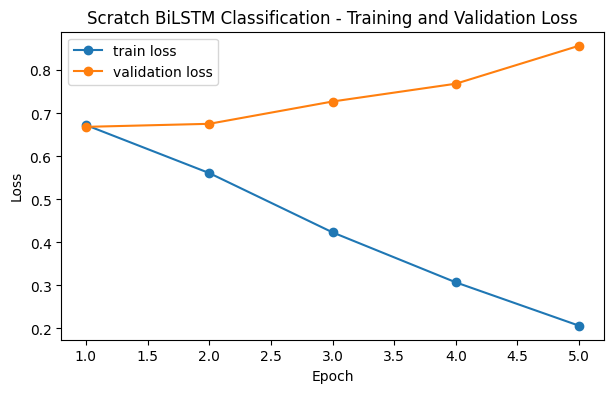

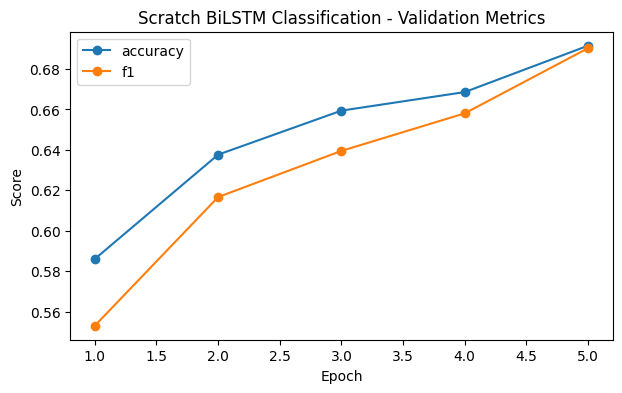

In [13]:
# Plot the classifier's loss and metric curves (see the overfitting note below).
show_history_curves(history_cls, title_prefix="Scratch BiLSTM Classification - ")


> **Debug checkpoint - read the curves, not just the final number.**
>
> Look at the two plots above together:
>
> - **Training loss keeps falling** while **validation loss flattens or turns back up.** That gap is **overfitting**: the model is memorising the training set instead of learning to generalise. On this tiny SST-2 subset it shows up within a couple of epochs.
> - **Validation F1 is the number we actually optimise**, and it can still inch up for an epoch or two after the loss has turned - which is why early stopping here watches **F1**, keeps the best-F1 weights, and discards whatever came after.
>
> **What a researcher does next:** lower the learning rate, add dropout / weight decay, get more data (see Experiment 3), or shrink the model. You almost never accept the first training run - you read the curve and adjust. The next cell applies several of these at once (more data, dropout, weight decay, label smoothing) so you can watch the curve straighten out; in a real sweep you would change one knob at a time to attribute the gain.


## Fixing the Overfit - More Data + Regularization

The Debug checkpoint above is a diagnosis, not a dead end. Let's turn the knobs it names and retrain - changing five things at once, all pushing the same direction:

| Knob | First run | Fix run | Why it helps the *loss* curve |
|---|---|---|---|
| training examples | 4000 | 8000 | more signal per class -> less to memorise |
| head dropout | 0.2 | 0.5 | stochastic regularisation before the classifier |
| weight decay | 0 | 1e-1 (AdamW) | L2 pressure against the extreme weights that drive overconfidence |
| label smoothing | 0 | 0.1 | caps target confidence, so a confident *wrong* prediction no longer blows up cross-entropy |
| learning rate | 1e-3 | 5e-4 | a gentler step so validation loss bottoms nearer the epoch budget instead of turning up early |

**Label smoothing is the knob aimed straight at our symptom.** The first run's validation loss climbed because the model became *confidently wrong*, and cross-entropy punishes that super-linearly even while accuracy and F1 keep rising. Smoothing removes the incentive to push logits to extremes, so the validation-loss curve flattens instead of diverging.

We hold the **vocabulary fixed** (still built from the first 4000 sentences) so the only things that change are the number of training examples, the regularisation, and the optimiser settings - a cleaner before/after than if we also grew the embedding table. We also bump the transformers to the same 8000 examples (`HF_TRAIN_SIZE`) so the Part F comparison stays a matched-budget one. Everything downstream - prediction inspection and the Part F table - now uses this fixed model.

> **Reading note:** label smoothing raises the absolute loss floor, so the fixed run's loss values are not directly comparable to the first run's. Read the *shape* - does validation loss still pull away from training loss? - and the train/val *gap*, not the raw numbers.

{'epoch': 1, 'train_loss': 0.6934674024581909, 'loss': 0.7037871736998952, 'accuracy': 0.5137614678899083, 'f1': 0.3536540169362339}
{'epoch': 2, 'train_loss': 0.6552822661399841, 'loss': 0.6838030142521639, 'accuracy': 0.5584862385321101, 'f1': 0.4960180744143454}
{'epoch': 3, 'train_loss': 0.6188441252708435, 'loss': 0.6729172604893325, 'accuracy': 0.5940366972477065, 'f1': 0.5783872377622378}
{'epoch': 4, 'train_loss': 0.5626111531257629, 'loss': 0.6851642640358812, 'accuracy': 0.5974770642201835, 'f1': 0.5887538545256666}
{'epoch': 5, 'train_loss': 0.4834763121604919, 'loss': 0.7259145297041727, 'accuracy': 0.5940366972477065, 'f1': 0.5809672742673768}


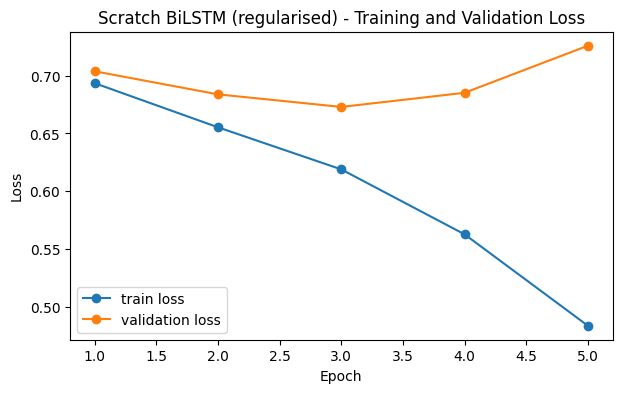

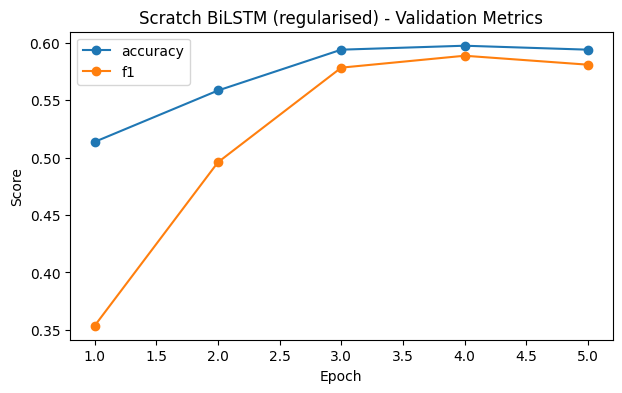

,run,best_val_f1,final_loss_gap
0,"first (4000, no reg)",0.6903,0.6510
1,"fixed (8000, +reg)",0.5888,0.2424


In [14]:
# Re-run the scratch BiLSTM with the Debug-checkpoint fixes applied together:
# 2x the data, stronger dropout, weight decay, and label smoothing. We keep the
# first run's history (history_cls) so we can show the before/after.

# Bigger training set. Same SEED as train_cls, so its first 4000 rows are identical
# and the extra 4000 are genuinely *new* examples (a clean superset).
train_cls_big = raw_cls["train"].shuffle(seed=SEED).select(range(CLS_FIX_TRAIN_SIZE))
train_cls_fix_loader = DataLoader(
    SST2Dataset(train_cls_big, vocab, max_len=max_len_cls),   # SAME vocab as the first run
    batch_size=64, shuffle=True, collate_fn=collate_cls,
)

# Fresh model (only the head dropout differs from the first run). Rebinding
# `model_cls` makes every downstream cell use this regularised version.
model_cls = LSTMTextClassifier(vocab_size=len(vocab), bidirectional=True, dropout=0.5).to(device)
history_cls_reg = train_cls_model(
    model_cls, train_cls_fix_loader, valid_cls_loader,
    lr=5e-4, weight_decay=1e-1, label_smoothing=0.1,
)

# Refresh the numbers Part F reads, so the headline comparison uses the FIXED model.
scratch_cls_f1 = max(row["f1"] for row in history_cls_reg)
scratch_cls_params = count_trainable_parameters(model_cls)

# The regularised run's train and validation loss should track each other far more
# closely than the first run's did.
show_history_curves(history_cls_reg, title_prefix="Scratch BiLSTM (regularised) - ")

# Before/after summary. best_val_f1 is unaffected by label smoothing; the final
# val-minus-train loss GAP is the overfitting signal and is roughly scale-robust
# (smoothing lifts both losses by a similar floor), so it is fair to compare.
pd.DataFrame([
    {"run": "first (4000, no reg)",
     "best_val_f1": round(max(r["f1"] for r in history_cls), 4),
     "final_loss_gap": round(history_cls[-1]["loss"] - history_cls[-1]["train_loss"], 4)},
    {"run": "fixed (8000, +reg)",
     "best_val_f1": round(max(r["f1"] for r in history_cls_reg), 4),
     "final_loss_gap": round(history_cls_reg[-1]["loss"] - history_cls_reg[-1]["train_loss"], 4)},
])

> ## Intuition Check - LSTM Classification
>
> Pause before reading the answers: what role does the final hidden state play?
>
> - We use the final hidden state because it is the model's compressed sentence representation.
> - Very long sentences can lose early details if the recurrent memory is not strong enough.
> - A bidirectional LSTM helps because the representation can use both left and right context.


In [14]:
# Run the trained model on ONE raw string and return class probabilities. This is
# the same pipeline as training (tokenize -> ids -> model) but for a single example.
def predict_scratch_cls(text, model=model_cls, vocab=vocab, max_len=max_len_cls):
    model.eval()
    tokens = simple_tokenize(text)[:max_len]
    if not tokens:
        tokens = [UNK_TOKEN]
    # Wrap in an extra [] to make a batch of size 1: shape (1, T).
    ids = torch.tensor([[vocab.get(token, UNK_ID) for token in tokens]], dtype=torch.long).to(device)
    lengths = torch.tensor([ids.shape[1]], dtype=torch.long).to(device)

    with torch.no_grad():
        # softmax turns raw logits into probabilities; squeeze drops the batch dim.
        probs = torch.softmax(model(ids, lengths), dim=-1).squeeze(0).cpu().numpy()

    return {"negative": float(probs[0]), "positive": float(probs[1])}


# Build a small table comparing true vs predicted label on the first n examples.
# Prediction tables surface failure patterns that a single F1 number hides.
def inspect_cls_predictions(model, examples, n=8):
    rows = []

    for item in examples.select(range(n)):
        text = item["sentence"]
        true_label = item["label"]

        probs = predict_scratch_cls(text, model=model)
        pred_label = int(probs["positive"] > probs["negative"])   # argmax over the two classes

        rows.append({
            "text": text,
            "true": "positive" if true_label == 1 else "negative",
            "pred": "positive" if pred_label == 1 else "negative",
            "p_negative": round(probs["negative"], 3),
            "p_positive": round(probs["positive"], 3),
        })

    return pd.DataFrame(rows)


inspect_cls_predictions(model_cls, valid_cls, n=8)


,text,true,pred,p_negative,p_positive
0,it 's a charming and often affecting journey .,positive,positive,0.000,1.000
1,unflinchingly bleak and desperate,negative,positive,0.382,0.618
2,allows us to hope that nolan is poised to emba...,positive,positive,0.255,0.745
3,"the acting , costumes , music , cinematography...",positive,positive,0.359,0.641
4,"it 's slow -- very , very slow .",negative,negative,0.607,0.393
5,although laced with humor and a few fanciful t...,positive,negative,0.989,0.011
6,a sometimes tedious film .,negative,negative,0.690,0.310
7,or doing last year 's taxes with your ex-wife .,negative,negative,0.979,0.021


Metrics are useful, but prediction tables reveal model behavior.

Look for:

- repeated mistakes
- uncertainty on short or sarcastic examples
- confidence that seems too high
- examples where a keyword overwhelms the full sentence


> ## Your turn - test the classifier on your own text
>
> Edit `my_review` below and re-run the cell. Try an easy case, then something hard: sarcasm ("oh great, another sequel"), negation ("not bad at all"), or a mixed review. Where does this tiny from-scratch model get fooled, and how confident is it when it is wrong?


In [15]:
# YOUR TURN: change this string and re-run. predict_scratch_cls returns the
# model's probability for each class on a single raw sentence.
my_review = "the plot was predictable but the acting saved it"

probs = predict_scratch_cls(my_review)
print(f"text: {my_review!r}")
print(f"  negative={probs['negative']:.3f}   positive={probs['positive']:.3f}")
print(f"  prediction: {'positive' if probs['positive'] > probs['negative'] else 'negative'}")


text: 'the plot was predictable but the acting saved it'
  negative=1.000   positive=0.000
  prediction: negative


> ## Common Mistakes
>
> - Forgetting to pad batches.
> - Treating token IDs as meaningful numbers instead of categorical IDs.
> - Not using `padding_idx` in the embedding layer.
> - Using accuracy only when the dataset is imbalanced.
> - Overfitting a tiny dataset and thinking the model generalized.


## Classification: Theory to Code

| Theory concept | Code object |
|---|---|
| token | word / subword |
| vocabulary | `vocab` or tokenizer vocabulary |
| token ID | `input_ids` |
| sentence representation | final hidden state / `[CLS]` representation |
| classifier | linear layer / classification head |
| probability | `softmax(logits)` |
| loss | `CrossEntropyLoss` |


## Mini Experiment 1 - Remove Bidirectionality

A unidirectional LSTM reads left to right. A bidirectional LSTM reads both left to right and right to left.

We train both under the same budget and compare. The result is *not* a clean win for the BiLSTM: on short SST-2 sentences, where a few sentiment keywords usually decide the label, the extra right-to-left pass adds little. The two land within about a point of each other - and which one edges ahead even flips between runs - while the unidirectional model uses fewer parameters. Bidirectionality tends to pay off when later tokens disambiguate earlier ones, a pattern that is far more common in tagging (Part B) than in short-sentence sentiment.


In [16]:
model_cls_unidirectional = LSTMTextClassifier(
    vocab_size=len(vocab),
    bidirectional=False,
).to(device)

print("BiLSTM params:        ", count_trainable_parameters(model_cls))
print("Unidirectional params:", count_trainable_parameters(model_cls_unidirectional))

# Train the left-to-right model under the SAME budget (same EPOCHS, LR, early
# stopping) and compare to the BiLSTM above - only the direction differs.
history_cls_uni = train_cls_model(model_cls_unidirectional, train_cls_loader, valid_cls_loader)

# Report each model's BEST epoch (early stopping restored those weights).
def _best(history, key):
    return round(max(row[key] for row in history), 4)

pd.DataFrame([
    {"model": "BiLSTM", "direction": "bidirectional",
     "val_accuracy": _best(history_cls, "accuracy"), "val_f1": _best(history_cls, "f1")},
    {"model": "LSTM", "direction": "left-to-right",
     "val_accuracy": _best(history_cls_uni, "accuracy"), "val_f1": _best(history_cls_uni, "f1")},
])


BiLSTM params:         688514
Unidirectional params: 556162


{'epoch': 1, 'train_loss': 0.6834083247184753, 'loss': 0.6832151604354928, 'accuracy': 0.569954128440367, 'f1': 0.5473165005212091}


{'epoch': 2, 'train_loss': 0.6142164282798767, 'loss': 0.6538430977305141, 'accuracy': 0.6227064220183486, 'f1': 0.6181745344103151}


{'epoch': 3, 'train_loss': 0.49756649923324586, 'loss': 0.6420007030898278, 'accuracy': 0.6295871559633027, 'f1': 0.6283157579412576}


{'epoch': 4, 'train_loss': 0.39210601592063904, 'loss': 0.6540748455108852, 'accuracy': 0.6823394495412844, 'f1': 0.6786846428595184}


{'epoch': 5, 'train_loss': 0.2970040967464447, 'loss': 0.7355447635738128, 'accuracy': 0.6731651376146789, 'f1': 0.6711058292296556}


,model,direction,val_accuracy,val_f1
0,BiLSTM,bidirectional,0.6915,0.6903
1,LSTM,left-to-right,0.6823,0.6787


## Mini Experiment 2 - Change `max_len`

Small `max_len`:

- faster
- less memory
- more truncation

Large `max_len`:

- slower
- more memory
- less truncation


In [17]:
# Instead of retraining, we just COUNT the cost of each max_len choice: how many
# training sentences would be cut off (lose tokens) at that cap. This is the cheap
# way to pick max_len - trade truncation against wasted padding/compute.
max_len_values = [16, 32, 64, 128]

length_summary = []
for candidate in max_len_values:
    truncated = sum(length > candidate for length in lengths)   # sentences longer than the cap
    length_summary.append({
        "max_len": candidate,
        "truncated_examples": truncated,
        "truncated_fraction": truncated / len(lengths),          # share of data affected
    })

pd.DataFrame(length_summary)


,max_len,truncated_examples,truncated_fraction
0,16,791,0.19775
1,32,94,0.02350
2,64,0,0.00000
3,128,0,0.00000


## Mini Experiment 3 - Train on Less Data

Scratch models usually need more labeled data. Pretrained transformers can often adapt with less task-specific data.


{'epoch': 1, 'train_loss': 0.6879992518424988, 'loss': 0.6946791055005624, 'accuracy': 0.5286697247706422, 'f1': 0.43753678299640764}


{'epoch': 2, 'train_loss': 0.631239755153656, 'loss': 0.6927948769079436, 'accuracy': 0.533256880733945, 'f1': 0.49534669106721096}


{'epoch': 3, 'train_loss': 0.5889154267311096, 'loss': 0.6930087050166699, 'accuracy': 0.5412844036697247, 'f1': 0.5330205856521646}


{'epoch': 4, 'train_loss': 0.5449738731384277, 'loss': 0.6944272485348063, 'accuracy': 0.5504587155963303, 'f1': 0.5503428099364894}


{'epoch': 5, 'train_loss': 0.5003802118301391, 'loss': 0.7006502009313041, 'accuracy': 0.5573394495412844, 'f1': 0.5543008474576271}


{'epoch': 1, 'train_loss': 0.6880446729660035, 'loss': 0.7029032920478681, 'accuracy': 0.5149082568807339, 'f1': 0.40045154358663443}


... (10 outputs left out)

{'epoch': 2, 'train_loss': 0.5718425135612488, 'loss': 0.6456253878567197, 'accuracy': 0.6032110091743119, 'f1': 0.6023743252361673}


{'epoch': 3, 'train_loss': 0.44262756276130677, 'loss': 0.654597861504336, 'accuracy': 0.6479357798165137, 'f1': 0.6447169523354501}


{'epoch': 4, 'train_loss': 0.3097996187210083, 'loss': 0.7120631348102464, 'accuracy': 0.6307339449541285, 'f1': 0.6297034821461541}


{'epoch': 5, 'train_loss': 0.2041728527545929, 'loss': 0.8356976235678436, 'accuracy': 0.6651376146788991, 'f1': 0.6645004875220702}


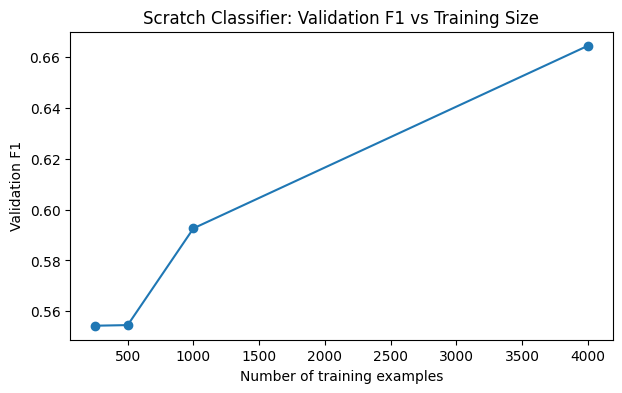

,train_size,val_f1
0,250,0.554301
1,500,0.554547
2,1000,0.592633
3,4000,0.664500


In [18]:
train_sizes = [250, 500, 1000, 4000]

# Train a fresh classifier on progressively more data (same budget each time)
# and watch validation F1 climb. This is the "data is a hyperparameter" lesson:
# from-scratch models are hungry, which is exactly what pretraining fixes.
data_size_rows = []
for size in train_sizes:
    subset_loader = DataLoader(
        SST2Dataset(train_cls.select(range(size)), vocab, max_len=max_len_cls),
        batch_size=64, shuffle=True, collate_fn=collate_cls,
    )
    scratch_model = LSTMTextClassifier(vocab_size=len(vocab), bidirectional=True).to(device)
    hist = train_cls_model(scratch_model, subset_loader, valid_cls_loader)
    data_size_rows.append({"train_size": size, "val_f1": max(row["f1"] for row in hist)})

data_size_summary = pd.DataFrame(data_size_rows)

plt.figure(figsize=(7, 4))
plt.plot(data_size_summary["train_size"], data_size_summary["val_f1"], marker="o")
plt.title("Scratch Classifier: Validation F1 vs Training Size")
plt.xlabel("Number of training examples")
plt.ylabel("Validation F1")
plt.show()

data_size_summary


# Part B - From-scratch Sequence Tagging

> ## Theory Card - Sequence Tagging
>
> Sequence tagging maps each input token to a label.
>
> Examples:
>
> - token -> part of speech
> - token -> named entity tag
> - token -> chunk label
>
> The model must keep token-level hidden states instead of compressing the whole sequence into one vector.


![Sequence tagging pipeline](assets/sequence_tagging.svg)


In [19]:
# conll2003 on the Hub is a script-based dataset; `datasets>=4` dropped script
# loading, so we use the parquet mirror, which has the identical schema.
raw_ner = load_dataset("tomaarsen/conll2003")

# `ner_tags` is a sequence of class IDs; `.feature.names` maps ID -> tag string
# in the BIO scheme (B-PER, I-PER, ... O). We need this mapping everywhere we
# turn predictions back into human-readable tags.
label_names = raw_ner["train"].features["ner_tags"].feature.names

train_ner = raw_ner["train"].shuffle(seed=SEED).select(range(NER_TRAIN_SIZE))
valid_ner = raw_ner["validation"].select(range(1000))

label_names


['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']

## NER Tag Distribution

NER datasets are usually highly imbalanced. Most tokens are `O`, meaning they are not part of a named entity.

This is why entity-level F1 is more informative than token-level accuracy.


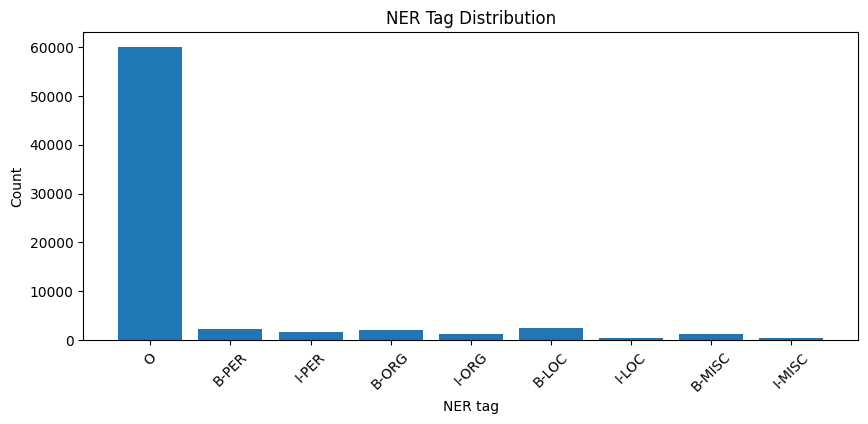

In [20]:
# Flatten every sentence's tag list into one long list of tag-ids, then count them.
all_tags = []
for tags in train_ner["ner_tags"]:
    all_tags.extend(tags)

tag_counts = pd.Series(all_tags).value_counts().sort_index()
tag_counts.index = [label_names[i] for i in tag_counts.index]   # tag-id -> tag string

# The bar chart makes the imbalance obvious: `O` (not-an-entity) dwarfs every entity
# tag. That is why we report entity-level seqeval F1, not token accuracy - a model
# that predicts `O` everywhere would still score high on raw accuracy.
plt.figure(figsize=(10, 4))
plt.bar(tag_counts.index, tag_counts.values)
plt.title("NER Tag Distribution")
plt.xlabel("NER tag")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()


## Tensor Shape Walkthrough - Sequence Tagging

For batch size `B`, sequence length `T`, embedding dimension `E`, hidden size `H`, and tag count `K`:

| Object | Shape | Meaning |
|---|---:|---|
| `input_ids` | `(B, T)` | token IDs |
| `embedded` | `(B, T, E)` | token vectors |
| `lstm_outputs` | `(B, T, 2H)` | contextual token vectors |
| `logits` | `(B, T, K)` | tag scores for each token |
| `labels` | `(B, T)` | true tag IDs |


In [21]:
# Same idea as build_vocab, but CoNLL is already tokenized into word lists, so we
# tally those words directly. min_freq=1 keeps every word (NER leans on rare proper
# nouns, so we do not want to throw them into <unk>).
def build_token_vocab(token_sequences, min_freq=1, max_size=20000):
    counts = Counter()
    for tokens in token_sequences:
        counts.update(token.lower() for token in tokens)   # lowercase for a smaller vocab

    vocab = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}
    for token, freq in counts.most_common(max_size - len(vocab)):
        if freq < min_freq:
            break
        vocab[token] = len(vocab)
    return vocab


ner_vocab = build_token_vocab(train_ner["tokens"], min_freq=1, max_size=20000)
len(ner_vocab)


12125

In [22]:
# -100 is PyTorch's CrossEntropyLoss "ignore me" sentinel. We pad LABELS with it so
# padded time steps contribute zero to the loss (more on this in the loss microscope).
IGNORE_INDEX = -100


# Tagging dataset: unlike classification, each example has ONE label PER TOKEN, so
# input_ids and labels are parallel sequences of the same length.
class NERDataset(Dataset):
    def __init__(self, split, vocab, max_len=96):
        self.split = split
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.split)

    def __getitem__(self, idx):
        item = self.split[idx]
        tokens = item["tokens"][: self.max_len]          # truncate tokens and...
        labels = item["ner_tags"][: self.max_len]        # ...their tags together (stay aligned)
        input_ids = [self.vocab.get(token.lower(), UNK_ID) for token in tokens]
        return {
            "input_ids": torch.tensor(input_ids, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.long),
            "tokens": tokens,
        }


# Like collate_cls, but note the KEY difference: labels are padded with IGNORE_INDEX
# (not 0), because 0 is the real tag `O` - padding must not look like a valid tag.
def collate_ner(batch):
    lengths = torch.tensor([len(item["input_ids"]) for item in batch], dtype=torch.long)
    max_len = int(lengths.max().item())
    input_ids = torch.full((len(batch), max_len), PAD_ID, dtype=torch.long)        # pad inputs with PAD_ID
    labels = torch.full((len(batch), max_len), IGNORE_INDEX, dtype=torch.long)     # pad labels with -100
    tokens = [item["tokens"] for item in batch]

    for i, item in enumerate(batch):
        ids = item["input_ids"]
        labs = item["labels"]
        input_ids[i, : len(ids)] = ids       # real tokens then PAD_ID
        labels[i, : len(labs)] = labs        # real tags then -100

    attention_mask = input_ids.ne(PAD_ID)
    return {
        "input_ids": input_ids,
        "lengths": lengths,
        "attention_mask": attention_mask,
        "labels": labels,
        "tokens": tokens,
    }


train_ner_ds = NERDataset(train_ner, ner_vocab, max_len=96)
valid_ner_ds = NERDataset(valid_ner, ner_vocab, max_len=96)

train_ner_loader = DataLoader(train_ner_ds, batch_size=32, shuffle=True, collate_fn=collate_ner)
valid_ner_loader = DataLoader(valid_ner_ds, batch_size=64, shuffle=False, collate_fn=collate_ner)

# Confirm the shapes: both input_ids and labels are (B, T) - one label per token.
ner_batch = next(iter(train_ner_loader))
print("input_ids:", ner_batch["input_ids"].shape)
print("labels:", ner_batch["labels"].shape)


input_ids: torch.Size([32, 40])
labels: torch.Size([32, 40])


## Implementation Blueprint - LSTM Tagger as Pieces

The tagger uses the same embedding and BiLSTM idea, but the head is applied at every time step.

![LSTM tagger blueprint](assets/tagger_blueprint.svg)


In [23]:
# Same preview idea as the classifier, but watch the KEY difference at the end:
# the head is applied to EVERY token state, not just the final one.
tag_preview_embedding = nn.Embedding(len(ner_vocab), 8, padding_idx=PAD_ID)
tag_preview_encoder = nn.LSTM(8, 16, batch_first=True, bidirectional=True)
tag_preview_head = nn.Linear(32, len(label_names))      # 32 -> one score per tag

tag_preview_ids = ner_batch["input_ids"][:2]            # 2 example sentences
tag_preview_lengths = ner_batch["lengths"][:2]

tag_preview_embedded = tag_preview_embedding(tag_preview_ids)
tag_preview_packed = pack_padded_sequence(
    tag_preview_embedded,
    tag_preview_lengths,
    batch_first=True,
    enforce_sorted=False,
)
tag_preview_packed_outputs, _ = tag_preview_encoder(tag_preview_packed)
# total_length pads back to the original T so logits line up with the label tensor.
tag_preview_outputs, _ = pad_packed_sequence(
    tag_preview_packed_outputs,
    batch_first=True,
    total_length=tag_preview_ids.size(1),
)
# Head applied at every time step -> (B, T, num_tags): a tag distribution per token.
tag_preview_logits = tag_preview_head(tag_preview_outputs)

pd.DataFrame([
    {"stage": "input IDs", "shape": tuple(tag_preview_ids.shape), "meaning": "token IDs"},
    {"stage": "embedding", "shape": tuple(tag_preview_embedded.shape), "meaning": "token vectors"},
    {"stage": "token states", "shape": tuple(tag_preview_outputs.shape), "meaning": "one contextual vector per token"},
    {"stage": "tag logits", "shape": tuple(tag_preview_logits.shape), "meaning": "tag scores per token"},
])


,stage,shape,meaning
0,input IDs,"(2, 40)",token IDs
1,embedding,"(2, 40, 8)",token vectors
2,token states,"(2, 40, 32)",one contextual vector per token
3,tag logits,"(2, 40, 9)",tag scores per token


In [24]:
# The tagger reuses the classifier's embedding+BiLSTM, but the head runs at every
# token. The crucial change vs. classification: we keep ALL hidden states, not h_n.
class LSTMTokenTagger(nn.Module):
    def __init__(
        self,
        vocab_size,
        num_tags,                 # one output unit per NER tag (here 9)
        embedding_dim=128,
        hidden_size=128,
        bidirectional=True,
        padding_idx=PAD_ID,
        dropout=0.2,
    ):
        super().__init__()
        self.bidirectional = bidirectional
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=padding_idx)
        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_size,
            batch_first=True,
            bidirectional=bidirectional,
        )
        hidden_factor = 2 if bidirectional else 1
        self.dropout = nn.Dropout(dropout)
        # Per-token classifier: maps each token's 2H vector to num_tags scores.
        self.classifier = nn.Linear(hidden_size * hidden_factor, num_tags)

    def forward(self, input_ids, lengths=None, return_shapes=False):
        embedded = self.embedding(input_ids)            # (B, T) -> (B, T, E)

        if lengths is not None:
            packed = pack_padded_sequence(
                embedded,
                lengths.cpu(),
                batch_first=True,
                enforce_sorted=False,
            )
            packed_outputs, _ = self.lstm(packed)
            # total_length restores the padded T so logits stay aligned with labels.
            lstm_outputs, _ = pad_packed_sequence(
                packed_outputs,
                batch_first=True,
                total_length=input_ids.size(1),
            )
        else:
            lstm_outputs, _ = self.lstm(embedded)

        # Apply the head to EVERY token state -> (B, T, num_tags). No pooling: tagging
        # needs a decision per position, so we never collapse the time dimension.
        logits = self.classifier(self.dropout(lstm_outputs))

        if return_shapes:
            return logits, {
                "input_ids": tuple(input_ids.shape),
                "embedded": tuple(embedded.shape),
                "lstm_outputs": tuple(lstm_outputs.shape),
                "logits": tuple(logits.shape),
            }
        return logits


# Build the tagger: num_tags = number of NER labels (one output unit each).
model_ner = LSTMTokenTagger(
    vocab_size=len(ner_vocab),
    num_tags=len(label_names),
    bidirectional=True,
).to(device)

# Shape check: note logits are now (B, T, num_tags) - a score per tag PER TOKEN,
# versus (B, num_classes) for the sentence classifier.
with torch.no_grad():
    logits, shapes = model_ner(
        ner_batch["input_ids"].to(device),
        ner_batch["lengths"].to(device),
        return_shapes=True,
    )

for name, shape in shapes.items():
    print(f"{name}: {shape}")
print("trainable params:", count_trainable_parameters(model_ner))


input_ids: (32, 40)
embedded: (32, 40, 128)
lstm_outputs: (32, 40, 256)
logits: (32, 40, 9)
trainable params: 1818505


## Loss Microscope - Token Tagging

For tagging, the model predicts a tag distribution at every token position. The loss flattens `(B, T, K)` into `(B*T, K)` and ignores padding labels set to `-100`.

![Token tagging loss microscope](assets/tagging_loss.svg)


In [25]:
# Inspect the exact tensors that feed token-level cross entropy.
with torch.no_grad():
    ner_demo_logits = model_ner(
        ner_batch["input_ids"].to(device),
        ner_batch["lengths"].to(device),
    )

ner_demo_labels = ner_batch["labels"].to(device)
# CrossEntropyLoss wants 2D logits and 1D targets, so we FLATTEN the batch and time
# dims together: (B, T, K) -> (B*T, K) and (B, T) -> (B*T,). The token order is
# preserved, so each flat logit row still lines up with its flat label.
flat_logits = ner_demo_logits.view(-1, ner_demo_logits.size(-1))
flat_labels = ner_demo_labels.view(-1)
# How many flattened positions are real tokens vs -100 padding. The loss only looks
# at the "active" ones; the ignored ones (padding) contribute nothing.
active_positions = flat_labels.ne(IGNORE_INDEX).sum().item()
ignored_positions = flat_labels.eq(IGNORE_INDEX).sum().item()

pd.DataFrame([
    {"object": "ner_demo_logits", "shape_or_count": tuple(ner_demo_logits.shape), "meaning": "scores for each token/tag"},
    {"object": "flat_logits", "shape_or_count": tuple(flat_logits.shape), "meaning": "cross-entropy input"},
    {"object": "flat_labels", "shape_or_count": tuple(flat_labels.shape), "meaning": "cross-entropy targets"},
    {"object": "active positions", "shape_or_count": active_positions, "meaning": "real tokens that affect loss"},
    {"object": "ignored positions", "shape_or_count": ignored_positions, "meaning": "padding tokens ignored by loss"},
])


,object,shape_or_count,meaning
0,ner_demo_logits,"(32, 40, 9)",scores for each token/tag
1,flat_logits,"(1280, 9)",cross-entropy input
2,flat_labels,"(1280,)",cross-entropy targets
3,active positions,444,real tokens that affect loss
4,ignored positions,836,padding tokens ignored by loss


In [26]:
def train_one_epoch_ner(model, loader, optimizer, criterion):
    # Identical four-step loop to classification; the only change is the flatten
    # before the loss (token-level instead of sentence-level).
    model.train()
    total_loss = 0.0

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        lengths = batch["lengths"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        logits = model(input_ids, lengths)
        # Flatten (B,T,K)->(B*T,K) and (B,T)->(B*T); criterion has ignore_index=-100
        # so padded positions are skipped automatically.
        loss = criterion(logits.view(-1, logits.size(-1)), labels.view(-1))
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * input_ids.size(0)

    return total_loss / len(loader.dataset)


def evaluate_ner(model, loader, criterion):
    # Build two parallel lists of TAG-STRING sequences (true vs predicted) so we can
    # score with seqeval, which measures whole-entity F1 rather than per-token hits.
    model.eval()
    total_loss = 0.0
    flat_true = []          # flat token-level ids (for a simple accuracy)
    flat_pred = []
    true_sequences = []     # per-sentence lists of tag strings (for seqeval)
    pred_sequences = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            lengths = batch["lengths"].to(device)
            labels = batch["labels"].to(device)

            logits = model(input_ids, lengths)
            loss = criterion(logits.view(-1, logits.size(-1)), labels.view(-1))
            preds = logits.argmax(dim=-1)           # most likely tag per token

            total_loss += loss.item() * input_ids.size(0)

            # Rebuild per-sentence tag sequences, SKIPPING padded (-100) positions so
            # they never count toward the score.
            for pred_row, label_row in zip(preds.cpu().numpy(), labels.cpu().numpy()):
                seq_true = []
                seq_pred = []
                for pred_id, label_id in zip(pred_row, label_row):
                    if label_id == IGNORE_INDEX:
                        continue
                    flat_true.append(label_id)
                    flat_pred.append(pred_id)
                    seq_true.append(label_names[int(label_id)])   # id -> "B-PER" etc.
                    seq_pred.append(label_names[int(pred_id)])
                true_sequences.append(seq_true)
                pred_sequences.append(seq_pred)

    try:
        from seqeval.metrics import f1_score as seqeval_f1_score

        f1 = seqeval_f1_score(true_sequences, pred_sequences)
    except Exception:
        f1 = sklearn_f1_score(flat_true, flat_pred, average="macro")

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(flat_true, flat_pred),
        "f1": f1,
    }


def train_ner_model(model, train_loader, valid_loader, epochs=EPOCHS, lr=SCRATCH_LR, patience=PATIENCE):
    # ignore_index=-100 keeps padding (and, later, non-first subwords) out of the loss.
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
    history = []

    # Same early-stopping rule as classification, but the metric is entity-level
    # seqeval F1 (computed in evaluate_ner) - the number we actually care about.
    best_f1, best_state, stale = -1.0, None, 0

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch_ner(model, train_loader, optimizer, criterion)
        metrics = evaluate_ner(model, valid_loader, criterion)
        row = {"epoch": epoch, "train_loss": train_loss, **metrics}
        history.append(row)
        print(row)

        if metrics["f1"] > best_f1 + 1e-4:
            best_f1 = metrics["f1"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
            if stale >= patience:
                print(f"  early stopping at epoch {epoch}: no val-F1 gain for {patience} epoch(s)")
                break

    if best_state is not None:
        model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    return history


history_ner = train_ner_model(model_ner, train_ner_loader, valid_ner_loader)
scratch_ner_f1 = max(row["f1"] for row in history_ner)   # model is restored to this best epoch
scratch_ner_params = count_trainable_parameters(model_ner)


{'epoch': 1, 'train_loss': 0.80145107254982, 'loss': 0.582133905172348, 'accuracy': 0.8543126017123045, 'f1': np.float64(0.2993960310612597)}


{'epoch': 2, 'train_loss': 0.4677585727214813, 'loss': 0.385923082113266, 'accuracy': 0.8961296256987193, 'f1': np.float64(0.5243262163108154)}


{'epoch': 3, 'train_loss': 0.32107900476455686, 'loss': 0.29619448590278624, 'accuracy': 0.9133941838250902, 'f1': np.float64(0.612601748567983)}


{'epoch': 4, 'train_loss': 0.22410784990787505, 'loss': 0.251111811876297, 'accuracy': 0.924219910846954, 'f1': np.float64(0.6541307028360049)}


{'epoch': 5, 'train_loss': 0.15716657218933106, 'loss': 0.23298476338386537, 'accuracy': 0.9263426024198684, 'f1': np.float64(0.6745005875440657)}


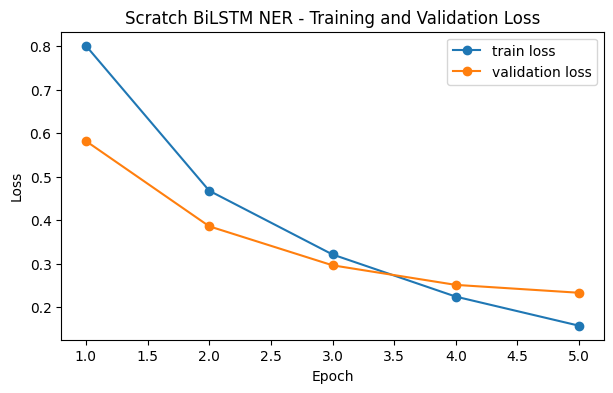

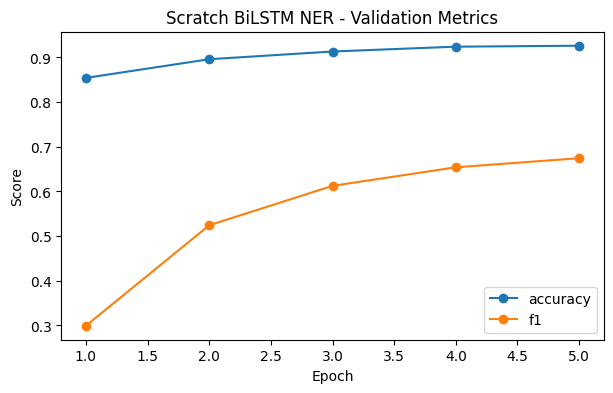

In [27]:
# Same curves for the tagger - watch entity-level F1 climb epoch over epoch.
show_history_curves(history_ner, title_prefix="Scratch BiLSTM NER - ")


> ## Intuition Check - LSTM Tagging
>
> Try answering first: what breaks if we keep only one final state?
>
> - We keep all hidden states because each token needs a tag.
> - `ignore_index=-100` prevents padding positions from contributing to the loss.
> - A BiLSTM helps NER because right context can disambiguate words like `Washington` or `Apple`.


In [28]:
# Tag one already-tokenized sentence (a list of words) and return a list of tag
# strings, one per input token - the tagging analogue of predict_scratch_cls.
def predict_scratch_ner(tokens, model=model_ner, vocab=ner_vocab, max_len=96):
    model.eval()
    trimmed = tokens[:max_len]
    ids = torch.tensor(                                     # batch of 1: shape (1, T)
        [[vocab.get(token.lower(), UNK_ID) for token in trimmed]],
        dtype=torch.long,
    ).to(device)
    lengths = torch.tensor([ids.shape[1]], dtype=torch.long).to(device)

    with torch.no_grad():
        # argmax over the tag dimension -> one predicted tag-id per token.
        pred_ids = model(ids, lengths).argmax(dim=-1).squeeze(0).cpu().numpy()

    # Map ids back to tag strings, trimmed to the real number of tokens.
    return [label_names[int(idx)] for idx in pred_ids[: len(trimmed)]]


def make_ner_prediction_table(tokens, true_tags, pred_tags):
    return pd.DataFrame({
        "token": tokens,
        "true_tag": true_tags,
        "pred_tag": pred_tags,
        "correct": [t == p for t, p in zip(true_tags, pred_tags)],
    })


example = valid_ner[0]
tokens = example["tokens"]
true_tags = [label_names[i] for i in example["ner_tags"]]
pred_tags = predict_scratch_ner(tokens)

make_ner_prediction_table(tokens, true_tags, pred_tags)


,token,true_tag,pred_tag,correct
0,CRICKET,O,O,True
1,-,O,O,True
2,LEICESTERSHIRE,B-ORG,B-ORG,True
3,TAKE,O,O,True
4,OVER,O,O,True
5,AT,O,O,True
6,TOP,O,B-LOC,False
7,AFTER,O,O,True
8,INNINGS,O,O,True
9,VICTORY,O,O,True


> ## Common Mistakes
>
> - Calculating loss on padding tokens.
> - Forgetting to align labels after subword tokenization.
> - Evaluating subword predictions as if they were original word predictions.
> - Reporting token accuracy only, which can be inflated by many `O` labels.


## Tagging: Theory to Code

| Theory concept | Code object |
|---|---|
| token-level label | NER tag |
| padding label | `-100` |
| ignored loss positions | `ignore_index=-100` |
| entity-level metric | `seqeval` |
| subword alignment | `word_ids()` |
| token classifier | `AutoModelForTokenClassification` |


# Part C - Transformer Tokenization

> ## Theory Card - Subword Tokenization
>
> Transformer tokenizers often split rare or complex words into subword pieces.
>
> This helps with rare words because the model can reuse pieces it has seen before. It also makes token classification harder because original word labels must be aligned to the produced subword pieces.


In [29]:
from transformers import AutoTokenizer

# Two checkpoints: uncased for sentiment (case rarely matters), CASED for NER
# (capitalisation is a strong entity signal - "apple" vs "Apple").
cls_checkpoint = "distilbert-base-uncased"
ner_checkpoint = "distilbert-base-cased"

# AutoTokenizer loads the EXACT tokenizer the model was pretrained with - it must
# match the checkpoint or the ids would mean nothing to the model.
tokenizer_cls = AutoTokenizer.from_pretrained(cls_checkpoint)
tokenizer_ner = AutoTokenizer.from_pretrained(ner_checkpoint)

# Watch subword splitting in action: rare/compound words break into WordPiece pieces
# (the "##" prefix marks a continuation of the previous piece).
sample_words = ["Washington", "unbelievably", "OpenAI"]
for word in sample_words:
    print(word, "->", tokenizer_ner.tokenize(word))


Washington -> ['Washington']
unbelievably -> ['un', '##bel', '##ie', '##va', '##bly']
OpenAI -> ['Open', '##A', '##I']


> ## Your turn - break your own words into subwords
>
> Put your own words in `my_words` and re-run. Try a rare or made-up word, a long compound, a name, an emoji, or a word with a typo. Notice how many pieces each becomes (`##` marks a continuation): a single common word is usually 1 piece, while rare words fragment - which is exactly how the model copes with words it never saw in pretraining.


In [30]:
# YOUR TURN: edit this list and re-run.
my_words = ["tokenization", "antidisestablishmentarianism", "Reinforcement", "covfefe"]
for word in my_words:
    pieces = tokenizer_ner.tokenize(word)
    print(f"{word!r:35} -> {len(pieces)} piece(s): {pieces}")


'tokenization'                      -> 2 piece(s): ['token', '##ization']
'antidisestablishmentarianism'      -> 8 piece(s): ['anti', '##dis', '##esta', '##b', '##lish', '##ment', '##arian', '##ism']
'Reinforcement'                     -> 4 piece(s): ['Re', '##in', '##force', '##ment']
'covfefe'                           -> 4 piece(s): ['co', '##v', '##fe', '##fe']


![Transformer fine-tuning path](assets/transformer_finetuning.svg)


In [31]:
# One call does everything the from-scratch pipeline did by hand: tokenize, map to
# ids, pad to equal length, and build the attention mask. return_tensors="pt" yields
# PyTorch tensors. Note the added [CLS]/[SEP] special tokens in the output ids.
encoded = tokenizer_cls(
    ["I loved this movie.", "This was not good."],
    padding=True,        # pad the shorter sentence up to the longer
    truncation=True,     # cut anything past the model's max length
    return_tensors="pt",
)

print("input_ids:", encoded["input_ids"].shape)
print("attention_mask:", encoded["attention_mask"].shape)
print(encoded)


input_ids: torch.Size([2, 7])
attention_mask: torch.Size([2, 7])
{'input_ids': tensor([[ 101, 1045, 3866, 2023, 3185, 1012,  102],
        [ 101, 2023, 2001, 2025, 2204, 1012,  102]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1]])}


> ## Intuition Check - Subword Tokenization
>
> Pause and inspect the tokenized examples before reading the answers.
>
> - Subwords help rare words because uncommon words can be built from known pieces.
> - Token classification gets harder because labels are usually defined on original words, not subword pieces.
> - Labeling only the first subword is simpler for word-level evaluation; labeling all subwords can add signal but changes what the loss sees.


> ## Theory Card - Label Alignment
>
> Word-level NER labels do not automatically fit subword-tokenized inputs.
>
> A word such as `unbelievable` may become several subword pieces. We need a rule that maps the original word label onto those pieces.
>
> **Practical warning:** evaluation should be clear about whether it scores original words or subword pieces.


## Mini Experiment 4 - First Subword Label vs All Subword Labels

Strategy A: label only the first subword and ignore later subwords with `-100`.

Strategy B: copy the same label to all subword pieces.

Ignoring later subwords simplifies evaluation. Labeling all subwords gives more training signal but may distort entity boundaries.


In [32]:
# THE core subtlety of token classification with subwords: our labels are per WORD,
# but the tokenizer produces per SUBWORD pieces. `word_ids` tells us which word each
# subword came from; this function spreads the word labels onto the subwords.
def align_labels_with_tokens(labels, word_ids, label_all_tokens=False):
    aligned = []
    previous_word_id = None

    for word_id in word_ids:
        if word_id is None:
            # Special tokens ([CLS]/[SEP]) map to no word -> ignore in the loss.
            aligned.append(IGNORE_INDEX)
        elif word_id != previous_word_id:
            # First subword of a word: give it that word's real label.
            aligned.append(labels[word_id])
        elif label_all_tokens:
            # Later subwords: copy the label (Strategy B - more signal).
            aligned.append(labels[word_id])
        else:
            # Later subwords: ignore them (Strategy A - default, cleaner eval).
            aligned.append(IGNORE_INDEX)
        previous_word_id = word_id

    return aligned


# Demo on one sentence. is_split_into_words=True tells the tokenizer the input is
# ALREADY a list of words (CoNLL is pre-tokenized), so word_ids() can be recovered.
sample = raw_ner["train"][0]
tokenized_sample = tokenizer_ner(sample["tokens"], is_split_into_words=True)
word_ids = tokenized_sample.word_ids()       # which original word each subword belongs to

# Side-by-side table: see how the two strategies label the subwords differently.
alignment_demo = pd.DataFrame({
    "subword": tokenizer_ner.convert_ids_to_tokens(tokenized_sample["input_ids"]),
    "word_id": word_ids,
    "first_subword_label": align_labels_with_tokens(sample["ner_tags"], word_ids, label_all_tokens=False),
    "all_subword_label": align_labels_with_tokens(sample["ner_tags"], word_ids, label_all_tokens=True),
})
alignment_demo


,subword,word_id,first_subword_label,all_subword_label
0,[CLS],NaN,-100,-100
1,EU,0.0,3,3
2,rejects,1.0,0,0
3,German,2.0,7,7
4,call,3.0,0,0
5,to,4.0,0,0
6,boycott,5.0,0,0
7,British,6.0,7,7
8,la,7.0,0,0
9,##mb,7.0,-100,0


# Part D - Full Transformer Fine-tuning

> ## Theory Card - Fine-tuning
>
> Fine-tuning starts with a pretrained model and updates it on a task-specific dataset.
>
> The pretrained encoder already knows a great deal about language. The task head learns how to use those representations for classification or tagging.
>
> **Practical trade-off:** full fine-tuning is strong, but it updates many parameters and stores a full model checkpoint.


## Trainer Anatomy - What Hugging Face Replaces

The `Trainer` is convenient, but it is not magic. It bundles the same pieces we built manually.

![Trainer anatomy](assets/trainer_anatomy.svg)


In [33]:
# Map each Trainer ingredient back to the manual piece we built by hand in Parts A/B.
pd.DataFrame([
    {"Trainer piece": "train_dataset / eval_dataset", "Manual equivalent": "DataLoader dataset"},
    {"Trainer piece": "data_collator", "Manual equivalent": "collate_fn with padding"},
    {"Trainer piece": "model", "Manual equivalent": "nn.Module"},
    {"Trainer piece": "TrainingArguments", "Manual equivalent": "optimizer/training hyperparameters"},
    {"Trainer piece": "compute_metrics", "Manual equivalent": "evaluate loop metric code"},
])


,Trainer piece,Manual equivalent
0,train_dataset / eval_dataset,DataLoader dataset
1,data_collator,collate_fn with padding
2,model,nn.Module
3,TrainingArguments,optimizer/training hyperparameters
4,compute_metrics,evaluate loop metric code


In [34]:
import evaluate
from transformers import (
    AutoModelForSequenceClassification,
    AutoModelForTokenClassification,
    DataCollatorWithPadding,
    DataCollatorForTokenClassification,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
)


def make_training_args(output_dir, epochs=EPOCHS, lr=HF_LR, early_stopping=True):
    # These TrainingArguments are the transformer equivalent of the scratch
    # training loop: LR, batch size, epochs, weight decay all live here.
    kwargs = {
        "output_dir": output_dir,
        "learning_rate": lr,
        "per_device_train_batch_size": 16,
        "per_device_eval_batch_size": 32,
        "num_train_epochs": epochs,
        "weight_decay": 0.01,            # mild L2 regularisation
        "logging_steps": 25,
        "report_to": [],                 # no W&B/TensorBoard for the workshop
    }

    # For early stopping the Trainer must evaluate AND checkpoint every epoch, then
    # reload the best checkpoint at the end - otherwise we'd keep the final (possibly
    # overfit) weights. This mirrors the best-F1 restore in the scratch loops above.
    if early_stopping:
        kwargs.update(
            save_strategy="epoch",
            save_total_limit=1,
            load_best_model_at_end=True,
            metric_for_best_model="f1",
            greater_is_better=True,
        )
    else:
        kwargs["save_strategy"] = "no"

    # `eval_strategy` was renamed from `evaluation_strategy`; support both versions.
    params = inspect.signature(TrainingArguments.__init__).parameters
    kwargs["eval_strategy" if "eval_strategy" in params else "evaluation_strategy"] = "epoch"

    return TrainingArguments(**kwargs)


def early_stopper():
    # Stop fine-tuning if validation F1 does not improve for PATIENCE evaluations.
    return [EarlyStoppingCallback(early_stopping_patience=PATIENCE)]


## Full Fine-tuning - Sequence Classification

Shape reminder:

| Object | Shape | Meaning |
|---|---:|---|
| `input_ids` | `(B, T)` | subword IDs |
| `attention_mask` | `(B, T)` | real-token mask |
| `logits` | `(B, C)` | class scores |
| `labels` | `(B,)` | true class IDs |


In [35]:
# Add input_ids/attention_mask columns to the dataset. No padding here - the
# collator pads per-batch later (dynamic padding wastes less than padding to a global max).
def tokenize_cls(batch):
    return tokenizer_cls(batch["sentence"], truncation=True)


# .map runs the tokenizer over the whole dataset (batched=True = fast, vectorised).
tokenized_cls = raw_cls.map(tokenize_cls, batched=True)
hf_train_cls = tokenized_cls["train"].shuffle(seed=SEED).select(range(HF_TRAIN_SIZE))
hf_valid_cls = tokenized_cls["validation"].select(range(872))

# DataCollatorWithPadding is the HF equivalent of our collate_cls: it pads each batch.
data_collator_cls = DataCollatorWithPadding(tokenizer=tokenizer_cls)
accuracy_metric = evaluate.load("accuracy")    # the `evaluate` library's metric implementations
f1_metric = evaluate.load("f1")


# The Trainer calls this on raw logits+labels after each eval. We argmax to predictions,
# then compute the same metrics as the scratch path (macro F1 + accuracy).
def compute_cls_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_metric.compute(predictions=preds, references=labels)["accuracy"],
        "f1": f1_metric.compute(predictions=preds, references=labels, average="macro")["f1"],
    }


# AutoModelForSequenceClassification = pretrained encoder + a fresh 2-class head on top.
# The warning about uninitialised head weights is EXPECTED - that head is what we train.
full_cls_model = AutoModelForSequenceClassification.from_pretrained(
    cls_checkpoint,
    num_labels=2,
).to(device)
full_cls_params = count_trainable_parameters(full_cls_model)   # ~67M: the WHOLE model trains

training_args_cls = make_training_args("outputs/full-distilbert-sst2")  # EPOCHS, HF_LR, early stopping
trainer_cls = Trainer(
    model=full_cls_model,
    args=training_args_cls,
    train_dataset=hf_train_cls,
    eval_dataset=hf_valid_cls,
    processing_class=tokenizer_cls,
    data_collator=data_collator_cls,
    compute_metrics=compute_cls_metrics,
    callbacks=early_stopper(),
)

trainer_cls.train()
hf_cls_metrics = trainer_cls.evaluate()
hf_cls_f1 = hf_cls_metrics.get("eval_f1", np.nan)
hf_cls_metrics


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.312700,0.404853,0.832569,0.829337
2,0.152700,0.420424,0.861239,0.861186
3,0.121900,0.570642,0.854358,0.853493
4,0.053900,0.652879,0.854358,0.853969


{'eval_loss': 0.420424222946167,
 'eval_accuracy': 0.8612385321100917,
 'eval_f1': 0.8611857728310277,
 'eval_runtime': 0.3347,
 'eval_samples_per_second': 2605.375,
 'eval_steps_per_second': 83.659,
 'epoch': 4.0}

## Full Fine-tuning - Token Classification

Shape reminder:

| Object | Shape | Meaning |
|---|---:|---|
| `input_ids` | `(B, T)` | subword IDs |
| `attention_mask` | `(B, T)` | real-token mask |
| `logits` | `(B, T, K)` | tag scores |
| `labels` | `(B, T)` | aligned tag IDs or `-100` |


In [36]:
# The model needs id<->label maps so its config stores human-readable tag names
# (and so predictions can be decoded back to "B-PER" etc.).
id2label = {i: name for i, name in enumerate(label_names)}
label2id = {name: i for i, name in id2label.items()}


# Tokenize each pre-split sentence AND realign its word labels onto the subwords,
# reusing align_labels_with_tokens from Part C - the bridge between word labels and
# subword inputs that makes transformer token-classification work.
def tokenize_and_align_labels(examples, label_all_tokens=False):
    tokenized = tokenizer_ner(
        examples["tokens"],
        truncation=True,
        is_split_into_words=True,        # input is already word-tokenized (CoNLL)
    )

    aligned_labels = []
    for i, labels in enumerate(examples["ner_tags"]):
        word_ids = tokenized.word_ids(batch_index=i)   # per-row subword->word map
        aligned_labels.append(
            align_labels_with_tokens(labels, word_ids, label_all_tokens=label_all_tokens)
        )

    tokenized["labels"] = aligned_labels   # attach the aligned label sequences
    return tokenized


# remove_columns drops the original text columns so only model inputs remain.
tokenized_ner = raw_ner.map(
    tokenize_and_align_labels,
    batched=True,
    remove_columns=raw_ner["train"].column_names,
)

hf_train_ner = tokenized_ner["train"].shuffle(seed=SEED).select(range(HF_TRAIN_SIZE))
hf_valid_ner = tokenized_ner["validation"].select(range(1000))

# This collator pads BOTH input_ids and labels (padding labels with -100) - the HF
# equivalent of our collate_ner.
data_collator_ner = DataCollatorForTokenClassification(tokenizer=tokenizer_ner)
seqeval_metric = evaluate.load("seqeval")    # entity-level precision/recall/F1


# Same rebuild-and-skip-padding logic as the scratch evaluate_ner, but starting from
# the Trainer's raw logits. seqeval then scores whole entities (it understands the
# B-/I- scheme), which is the metric that actually matters for NER.
def compute_ner_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    true_labels = []
    true_predictions = []
    for pred_row, label_row in zip(predictions, labels):
        row_labels = []
        row_preds = []
        for pred_id, label_id in zip(pred_row, label_row):
            if label_id == IGNORE_INDEX:        # skip the -100 (subword/padding) positions
                continue
            row_labels.append(label_names[int(label_id)])
            row_preds.append(label_names[int(pred_id)])
        true_labels.append(row_labels)
        true_predictions.append(row_preds)

    # seqeval returns entity-level precision/recall/F1 plus token accuracy.
    metrics = seqeval_metric.compute(predictions=true_predictions, references=true_labels)
    return {
        "precision": metrics["overall_precision"],
        "recall": metrics["overall_recall"],
        "f1": metrics["overall_f1"],            # the headline NER number
        "accuracy": metrics["overall_accuracy"],
    }


# AutoModelForTokenClassification = pretrained encoder + a PER-TOKEN tagging head.
# We pass id2label/label2id so the saved model knows its tag names.
full_ner_model = AutoModelForTokenClassification.from_pretrained(
    ner_checkpoint,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id,
).to(device)
full_ner_params = count_trainable_parameters(full_ner_model)

training_args_ner = make_training_args("outputs/full-distilbert-conll")  # EPOCHS, HF_LR, early stopping
trainer_ner = Trainer(
    model=full_ner_model,
    args=training_args_ner,
    train_dataset=hf_train_ner,
    eval_dataset=hf_valid_ner,
    processing_class=tokenizer_ner,
    data_collator=data_collator_ner,
    compute_metrics=compute_ner_metrics,
    callbacks=early_stopper(),
)

trainer_ner.train()
hf_ner_metrics = trainer_ner.evaluate()
hf_ner_f1 = hf_ner_metrics.get("eval_f1", np.nan)
hf_ner_metrics


Some weights of DistilBertForTokenClassification were not initialized from the model checkpoint at distilbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.090800,0.085345,0.827354,0.839590,0.833427,0.972334
2,0.059000,0.057841,0.907587,0.905006,0.906295,0.982523
3,0.044300,0.052611,0.903190,0.918089,0.910578,0.984080
4,0.024900,0.048430,0.920000,0.928896,0.924427,0.985990
5,0.022100,0.049415,0.909091,0.927190,0.918051,0.985070


{'eval_loss': 0.04842999950051308,
 'eval_precision': 0.92,
 'eval_recall': 0.928896473265074,
 'eval_f1': 0.924426832720068,
 'eval_accuracy': 0.9859902356187646,
 'eval_runtime': 0.3334,
 'eval_samples_per_second': 2999.141,
 'eval_steps_per_second': 95.972,
 'epoch': 5.0}

> **In practice - the fine-tuning knobs that actually matter.**
>
> Fine-tuning rarely fails on the model code; it fails on the settings around it. The ones worth knowing:
>
> - **Learning rate.** `2e-5` is the canonical starting point for BERT-family encoders. Too high and the pretrained knowledge is wiped out in the first few steps (catastrophic forgetting); too low and it never adapts. This is the first thing to sweep.
> - **Epochs + early stopping.** Fine-tuning needs *few* epochs (2-4 is typical) - the model already knows language. Early stopping, as wired in here, saves you from guessing.
> - **Effective batch size.** Limited by GPU memory. When a batch will not fit, use **gradient accumulation** (`gradient_accumulation_steps`) to simulate a larger one, and **mixed precision** (`fp16=True` / `bf16=True`) to fit more and train faster.
> - **Warmup + LR schedule.** A short linear warmup then decay stabilises those first fragile steps.
> - **Checkpointing + metric selection.** Always evaluate on a held-out set and keep the best checkpoint by your real metric, not the last one - exactly what `load_best_model_at_end` + `metric_for_best_model` do.
>
> **Interview-style question:** why is the fine-tuning learning rate (`2e-5`) so much smaller than the LoRA learning rate (`5e-4`) we use next?


> ## Common Mistakes
>
> - Using the wrong `AutoModelFor...` class.
> - Forgetting `is_split_into_words=True` for token classification.
> - Forgetting `DataCollatorForTokenClassification`.
> - Using too high a learning rate for full fine-tuning.
> - Comparing full fine-tuning and PEFT without checking trainable parameters.


# Part E - PEFT and LoRA

> ## Theory Card - PEFT
>
> Parameter-efficient fine-tuning freezes most pretrained weights and trains a small number of new parameters.
>
> This can reduce memory, speed up adaptation, and create smaller task-specific checkpoints.


> ## Theory Card - LoRA
>
> LoRA adds small trainable low-rank matrices to selected linear layers while keeping the original weight frozen.

![Full fine-tuning vs LoRA](assets/lora_comparison.svg)


> ## Intuition Check - PEFT and LoRA
>
> Think about the cost of storing one full model per task before reading the answers.
>
> - PEFT trains fewer parameters because most pretrained weights are frozen.
> - It can underperform full fine-tuning when the task needs large representational changes.
> - Small adapter checkpoints are useful because many task adapters can share one base model.


## LoRA Configuration Anatomy

Before wrapping the model, inspect what each LoRA setting changes.

![LoRA configuration anatomy](assets/lora_config.svg)


In [37]:
# Reference table of the LoRA knobs we set in the next cell, and why each matters.
pd.DataFrame([
    {"setting": "task_type", "value used here": "SEQ_CLS / TOKEN_CLS", "why it matters": "matches the downstream objective"},
    {"setting": "r", "value used here": 8, "why it matters": "controls adapter rank and parameter count"},
    {"setting": "lora_alpha", "value used here": "2 * r", "why it matters": "scales adapter contribution"},
    {"setting": "lora_dropout", "value used here": 0.1, "why it matters": "regularizes adapter training"},
    {"setting": "target_modules", "value used here": '["q_lin", "v_lin"]', "why it matters": "adds adapters to attention projections"},
])


,setting,value used here,why it matters
0,task_type,SEQ_CLS / TOKEN_CLS,matches the downstream objective
1,r,8,controls adapter rank and parameter count
2,lora_alpha,2 * r,scales adapter contribution
3,lora_dropout,0.1,regularizes adapter training
4,target_modules,"[""q_lin"", ""v_lin""]",adds adapters to attention projections


In [38]:
from peft import LoraConfig, TaskType, get_peft_model


def build_lora_sequence_classifier(r=8):
    # Start from the SAME pretrained checkpoint as full fine-tuning...
    base_model = AutoModelForSequenceClassification.from_pretrained(
        cls_checkpoint,
        num_labels=2,
    )
    config = LoraConfig(
        task_type=TaskType.SEQ_CLS,        # tells PEFT which head/objective to keep trainable
        r=r,                               # adapter rank: low rank = few extra params
        lora_alpha=2 * r,                  # scales the adapter's contribution (convention: 2*r)
        lora_dropout=0.1,                  # dropout applied inside the adapter
        target_modules=["q_lin", "v_lin"], # inject adapters into attention query/value projections
    )
    # ...then get_peft_model FREEZES the base weights and adds the trainable adapters.
    # The classifier head stays trainable; everything else is frozen.
    return get_peft_model(base_model, config).to(device)


peft_cls_model = build_lora_sequence_classifier(r=8)
peft_cls_params = count_trainable_parameters(peft_cls_model)     # just adapters + head
peft_cls_total_params = count_total_parameters(peft_cls_model)   # adapters + head + frozen base

# The headline PEFT statistic: trainable params are a TINY fraction of the total.
# Compare peft_cls_params here (~740K) to full_cls_params above (~67M).
print("trainable params:", peft_cls_params)
print("total params:", peft_cls_total_params)
print("trainable fraction:", peft_cls_params / peft_cls_total_params)
peft_cls_model.print_trainable_parameters()   # PEFT's own summary (trainable% etc.)


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 739586
total params: 67694596
trainable fraction: 0.010925332946813067
trainable params: 739,586 || all params: 67,694,596 || trainable%: 1.0925


## PEFT: Theory to Code

| Theory concept | Code object |
|---|---|
| freeze pretrained model | `requires_grad=False` internally |
| adapter configuration | `LoraConfig` |
| adapter-wrapped model | `get_peft_model(...)` |
| task type | `TaskType.SEQ_CLS` / `TaskType.TOKEN_CLS` |
| trainable parameter check | `print_trainable_parameters(model)` |


In [39]:
# Training is IDENTICAL to full fine-tuning - same Trainer, same data, same budget.
# The only differences: the model is LoRA-wrapped, and we use the larger LORA_LR.
training_args_peft_cls = make_training_args("outputs/lora-distilbert-sst2", lr=LORA_LR)  # same EPOCHS + early stopping
trainer_peft_cls = Trainer(
    model=peft_cls_model,
    args=training_args_peft_cls,
    train_dataset=hf_train_cls,
    eval_dataset=hf_valid_cls,
    processing_class=tokenizer_cls,
    data_collator=data_collator_cls,
    compute_metrics=compute_cls_metrics,
    callbacks=early_stopper(),
)

trainer_peft_cls.train()
peft_cls_metrics = trainer_peft_cls.evaluate()
peft_cls_f1 = peft_cls_metrics.get("eval_f1", np.nan)   # compare to hf_cls_f1 (full fine-tuning)
peft_cls_metrics


No label_names provided for model class `PeftModelForSequenceClassification`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.327900,0.357599,0.838303,0.837032
2,0.232700,0.356675,0.858945,0.858847
3,0.226800,0.369514,0.856651,0.856647
4,0.152700,0.425586,0.862385,0.862281
5,0.118600,0.459043,0.856651,0.856514


{'eval_loss': 0.42558589577674866,
 'eval_accuracy': 0.8623853211009175,
 'eval_f1': 0.8622809973045822,
 'eval_runtime': 0.2233,
 'eval_samples_per_second': 3904.281,
 'eval_steps_per_second': 125.367,
 'epoch': 5.0}

In [40]:
# Same recipe as the LoRA classifier, but task_type=TOKEN_CLS keeps the per-token
# tagging head trainable instead of a sentence head.
def build_lora_token_classifier(r=8):
    base_model = AutoModelForTokenClassification.from_pretrained(
        ner_checkpoint,
        num_labels=len(label_names),
        id2label=id2label,
        label2id=label2id,
    )
    config = LoraConfig(
        task_type=TaskType.TOKEN_CLS,      # token tagging objective
        r=r,
        lora_alpha=2 * r,
        lora_dropout=0.1,
        target_modules=["q_lin", "v_lin"],
    )
    return get_peft_model(base_model, config).to(device)


peft_ner_model = build_lora_token_classifier(r=8)
peft_ner_params = count_trainable_parameters(peft_ner_model)
peft_ner_model.print_trainable_parameters()   # again: a fraction of a percent trainable


Some weights of DistilBertForTokenClassification were not initialized from the model checkpoint at distilbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 154,377 || all params: 65,352,210 || trainable%: 0.2362


In [41]:
# LoRA fine-tuning for tagging - same Trainer machinery as full NER fine-tuning.
training_args_peft_ner = make_training_args("outputs/lora-distilbert-conll", lr=LORA_LR)  # same EPOCHS + early stopping
trainer_peft_ner = Trainer(
    model=peft_ner_model,
    args=training_args_peft_ner,
    train_dataset=hf_train_ner,
    eval_dataset=hf_valid_ner,
    processing_class=tokenizer_ner,
    data_collator=data_collator_ner,
    compute_metrics=compute_ner_metrics,
    callbacks=early_stopper(),
)

trainer_peft_ner.train()
peft_ner_metrics = trainer_peft_ner.evaluate()
peft_ner_f1 = peft_ner_metrics.get("eval_f1", np.nan)   # compare to hf_ner_f1 (full fine-tuning)
peft_ner_metrics


No label_names provided for model class `PeftModelForTokenClassification`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.121000,0.139987,0.755906,0.764505,0.760181,0.960235
2,0.090700,0.085278,0.838620,0.857224,0.847820,0.974457
3,0.089500,0.073633,0.865738,0.883959,0.874754,0.977853
4,0.070300,0.064130,0.885569,0.893629,0.889581,0.980259
5,0.071400,0.061889,0.894915,0.901024,0.897959,0.981391


{'eval_loss': 0.06188908591866493,
 'eval_precision': 0.8949152542372881,
 'eval_recall': 0.9010238907849829,
 'eval_f1': 0.8979591836734694,
 'eval_accuracy': 0.9813910705441166,
 'eval_runtime': 0.3764,
 'eval_samples_per_second': 2656.905,
 'eval_steps_per_second': 85.021,
 'epoch': 5.0}

> **In practice - why LoRA is everywhere now.**
>
> The numbers above only hint at why teams reach for LoRA in production:
>
> - **Tiny, swappable checkpoints.** An adapter is a few MB, not a few hundred. You keep **one** frozen base model in memory and hot-swap adapters per task / customer / language - instead of storing a full fine-tuned model for each.
> - **`target_modules` is a real choice.** Here we adapt the attention projections (`q_lin`, `v_lin`). Adding more modules (e.g. the feed-forward layers) raises capacity and parameter count - another dial to sweep alongside `r`.
> - **`r` and `lora_alpha`.** `r` sets adapter rank (capacity); `lora_alpha` scales its contribution. A common convention is `alpha = 2 * r` (used here). Experiment 5 below shows how F1 responds to `r`.
> - **Merge for inference.** `merge_and_unload()` folds the adapter back into the base weights, so there is **zero added latency** at serving time.
> - **QLoRA** goes further: quantise the frozen base to 4-bit, train LoRA on top, and fine-tune models that would not otherwise fit on a single GPU.


## Saving and Reloading a LoRA Adapter - the deploy step

Training is only useful if you can *ship* the result. This is the step most tutorials skip. With LoRA the deploy story is the headline feature: we save **only the adapter** (a few MB), keep one copy of the frozen base model around, and reattach the adapter to run inference. The three moves below - **save -> reload -> infer** - are exactly what a serving stack does.


In [42]:
import os
from peft import PeftModel

# 1. SAVE just the adapter. Note what is NOT written: the ~250MB frozen base. That
#    is the whole point - you store one base once and many tiny adapters beside it.
adapter_dir = "outputs/lora-sst2-adapter"
peft_cls_model.save_pretrained(adapter_dir)

adapter_mb = sum(
    os.path.getsize(os.path.join(adapter_dir, f))
    for f in os.listdir(adapter_dir)
    if os.path.isfile(os.path.join(adapter_dir, f))
) / 1e6
print(f"saved adapter -> {adapter_dir}  ({adapter_mb:.2f} MB on disk)")
print(f"for comparison, the full model has ~{full_cls_params/1e6:.0f}M parameters")

# 2. RELOAD from scratch: load the SAME frozen base, then attach the saved adapter.
#    (In production the base is loaded once and shared across every adapter.)
reload_base = AutoModelForSequenceClassification.from_pretrained(cls_checkpoint, num_labels=2)
reloaded_model = PeftModel.from_pretrained(reload_base, adapter_dir).to(device)
reloaded_model.eval()

# 3. INFER with the reloaded model on a brand-new sentence.
text = "an absolute masterpiece - I loved every minute"
enc = tokenizer_cls(text, return_tensors="pt", truncation=True).to(device)
with torch.no_grad():
    probs = torch.softmax(reloaded_model(**enc).logits, dim=-1).squeeze(0).cpu().numpy()
print()
print(f"reloaded model says: {text!r}")
print(f"  negative={probs[0]:.3f}   positive={probs[1]:.3f}")

# OPTIONAL: merge the adapter into the base weights for zero-overhead serving. The
# result is a plain model with no LoRA layers - identical outputs, full speed.
merged_model = reloaded_model.merge_and_unload()
print()
print("merged model type:", type(merged_model).__name__, "(adapter folded in, no PEFT wrapper)")


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


saved adapter -> outputs/lora-sst2-adapter  (2.97 MB on disk)
for comparison, the full model has ~67M parameters

reloaded model says: 'an absolute masterpiece - I loved every minute'
  negative=0.000   positive=1.000

merged model type: DistilBertForSequenceClassification (adapter folded in, no PEFT wrapper)


> ## Your turn - how do `r` and `target_modules` change the cost?
>
> Adjust the `(rank, modules)` pairs below and re-run. You are only *counting* trainable parameters (no training), so it is instant. DistilBERT's attention has `q_lin`, `k_lin`, `v_lin`, `out_lin`; its feed-forward has `lin1`, `lin2`. Notice how both a higher rank **and** adapting more modules grow the trainable count.


In [43]:
# YOUR TURN: edit these (rank, target_modules) pairs and re-run.
configs_to_try = [
    (4,  ["q_lin", "v_lin"]),
    (8,  ["q_lin", "v_lin"]),
    (8,  ["q_lin", "k_lin", "v_lin", "out_lin"]),       # all attention projections
    (8,  ["q_lin", "v_lin", "lin1", "lin2"]),           # attention + feed-forward
]
for rank, mods in configs_to_try:
    candidate = get_peft_model(
        AutoModelForSequenceClassification.from_pretrained(cls_checkpoint, num_labels=2),
        LoraConfig(task_type=TaskType.SEQ_CLS, r=rank, lora_alpha=2 * rank, target_modules=mods),
    )
    print(f"r={rank:<2} modules={mods}  ->  trainable params: {count_trainable_parameters(candidate):,}")


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


r=4  modules=['q_lin', 'v_lin']  ->  trainable params: 665,858
r=8  modules=['q_lin', 'v_lin']  ->  trainable params: 739,586
r=8  modules=['q_lin', 'k_lin', 'v_lin', 'out_lin']  ->  trainable params: 887,042


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


r=8  modules=['q_lin', 'v_lin', 'lin1', 'lin2']  ->  trainable params: 1,108,226


## Mini Experiment 5 - LoRA Rank Comparison

Higher rank gives the adapter more capacity, but increases trainable parameters.


In [44]:
r_values = [4, 8, 16, 32]

# This is a quick sweep, not the headline comparison, so we keep it cheap:
# 1 epoch and no early stopping. We only want the param-count-vs-F1 shape.
lora_rank_rows = []
for r in r_values:
    candidate = build_lora_sequence_classifier(r=r)
    rank_args = make_training_args(f"outputs/lora-rank-{r}", epochs=1, lr=LORA_LR, early_stopping=False)
    rank_trainer = Trainer(
        model=candidate,
        args=rank_args,
        train_dataset=hf_train_cls,
        eval_dataset=hf_valid_cls,
        processing_class=tokenizer_cls,
        data_collator=data_collator_cls,
        compute_metrics=compute_cls_metrics,
    )
    rank_trainer.train()
    rank_metrics = rank_trainer.evaluate()
    lora_rank_rows.append({
        "LoRA rank": r,
        "Trainable params": count_trainable_parameters(candidate),
        "Validation F1": round(rank_metrics["eval_f1"], 4),
    })
    del candidate, rank_trainer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

lora_rank_table = pd.DataFrame(lora_rank_rows)
lora_rank_table


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


No label_names provided for model class `PeftModelForSequenceClassification`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.335600,0.352479,0.842890,0.842888


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


No label_names provided for model class `PeftModelForSequenceClassification`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.336700,0.347067,0.850917,0.850889


... (3 outputs left out)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


No label_names provided for model class `PeftModelForSequenceClassification`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.321400,0.326425,0.856651,0.856651


,LoRA rank,Trainable params,Validation F1
0,4,665858,0.8429
1,8,739586,0.8509
2,16,887042,0.8543
3,32,1181954,0.8567


Read the table above as a capacity-vs-cost curve: trainable parameters grow steeply with rank, while validation F1 barely moves - the gains taper off fast relative to the extra parameters you pay for. That diminishing return is exactly why a small rank (`r=8` is a common default) is usually enough.


# Part F - Comparison and Recap

Everything below is computed live from the models trained above - and now they all share the **same budget**: the same maximum `EPOCHS` and the same early-stopping rule. Exact figures drift a little from run to run, but the pattern is the one the field repeats:

- **Pretraining wins on both tasks.** Full DistilBERT and LoRA clearly beat the from-scratch BiLSTM on classification *and* on NER. A model that has already read billions of words starts far ahead of one initialised from noise and shown only a few thousand sentences.
- **LoRA ~= full fine-tuning, at a fraction of the cost.** The two transformer rows land close together, yet LoRA trains well under 1% of the parameters. That gap between *score* and *trainable parameters* is the whole selling point of PEFT.
- **The scratch model is not useless.** It is small, transparent, and it taught us every moving part - embeddings, recurrence, padding, masking, the loss. It is simply out-gunned by transfer learning.

> **This is still not a true benchmark.** A rigorous comparison would also match the tokenisation (word-level vs subword), use identical training-set sizes, run several seeds, and search hyperparameters per model. Read these numbers as the *shape* of the trade-off, not a leaderboard. (Earlier we deliberately ran the transformers for only 1 epoch and saw them *lose* on NER - same models, unfair budget. Budget is part of the claim.)


In [45]:
# Pull each model's saved params/score from the global scope. global_or_nan returns
# NaN if a cell was skipped, so the table still builds even on a partial run.
def global_or_nan(name):
    return globals().get(name, np.nan)


# One row per (model, task): trainable parameter count vs validation F1. This table
# is the whole session in six rows - score against cost.
results = pd.DataFrame([
    {
        "model": "Scratch BiLSTM",
        "task": "classification",
        "trainable_params": global_or_nan("scratch_cls_params"),
        "score": global_or_nan("scratch_cls_f1"),
    },
    {
        "model": "Full DistilBERT",
        "task": "classification",
        "trainable_params": global_or_nan("full_cls_params"),
        "score": global_or_nan("hf_cls_f1"),
    },
    {
        "model": "LoRA DistilBERT",
        "task": "classification",
        "trainable_params": global_or_nan("peft_cls_params"),
        "score": global_or_nan("peft_cls_f1"),
    },
    {
        "model": "Scratch BiLSTM",
        "task": "NER",
        "trainable_params": global_or_nan("scratch_ner_params"),
        "score": global_or_nan("scratch_ner_f1"),
    },
    {
        "model": "Full DistilBERT",
        "task": "NER",
        "trainable_params": global_or_nan("full_ner_params"),
        "score": global_or_nan("hf_ner_f1"),
    },
    {
        "model": "LoRA DistilBERT",
        "task": "NER",
        "trainable_params": global_or_nan("peft_ner_params"),
        "score": global_or_nan("peft_ner_f1"),
    },
])

results


,model,task,trainable_params,score
0,Scratch BiLSTM,classification,688514,0.690282
1,Full DistilBERT,classification,66955010,0.861186
2,LoRA DistilBERT,classification,739586,0.862281
3,Scratch BiLSTM,NER,1818505,0.674501
4,Full DistilBERT,NER,65197833,0.924427
5,LoRA DistilBERT,NER,154377,0.897959


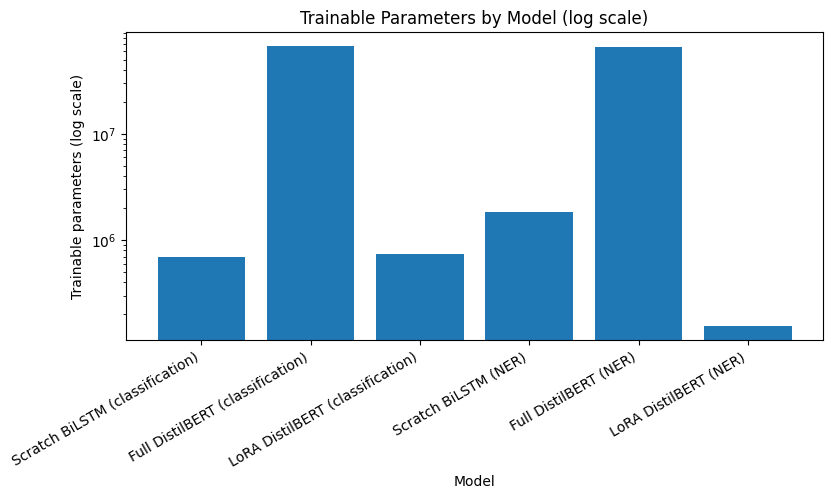

In [46]:
# Drop rows whose params are NaN (skipped models), then plot training cost.
plot_results = results.dropna(subset=["trainable_params"])

plt.figure(figsize=(9, 4))
plt.bar(plot_results["model"] + " (" + plot_results["task"] + ")", plot_results["trainable_params"])
plt.title("Trainable Parameters by Model (log scale)")
plt.xlabel("Model")
plt.ylabel("Trainable parameters (log scale)")
plt.yscale("log")  # full fine-tuning is ~100x the others; linear scale hides the small bars
plt.xticks(rotation=30, ha="right")
plt.show()


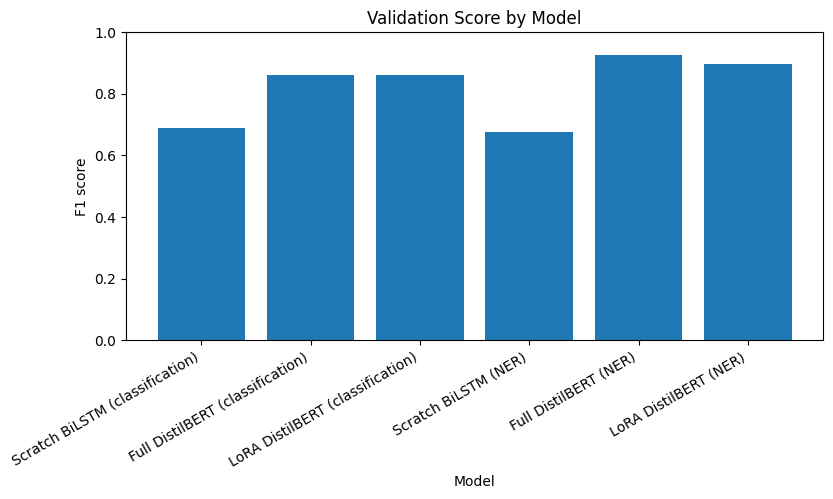

In [47]:
# Same models, now plotted by quality. Read this chart TOGETHER with the one above:
# LoRA reaches near-full-fine-tuning F1 while sitting near the bottom of the (log)
# parameter chart - that score-for-pennies gap is the takeaway of the whole session.
score_results = results.dropna(subset=["score"])

plt.figure(figsize=(9, 4))
plt.bar(score_results["model"] + " (" + score_results["task"] + ")", score_results["score"])
plt.title("Validation Score by Model")
plt.xlabel("Model")
plt.ylabel("F1 score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)   # fixed 0-1 axis so bar heights are comparable at a glance
plt.show()


# Final Recap

In this session, we moved through three levels of NLP modeling.

## 1. From scratch

We implemented LSTM models to understand the mechanics:

- embeddings
- recurrent hidden states
- final hidden state for classification
- per-token hidden states for tagging
- padding and masking

## 2. Pretrained transformers

We used Hugging Face to fine-tune pretrained models:

- tokenizers
- dynamic padding
- task-specific model heads
- `Trainer`
- sequence classification
- token classification
- label alignment

## 3. Efficient fine-tuning

We introduced PEFT and LoRA:

- freeze most pretrained parameters
- add small trainable adapters
- reduce trainable parameter count
- keep performance competitive

## Main takeaway

Scratch models help us understand the machinery - every layer in Part A and B was something we could read end to end.

Transformers give us strong pretrained representations: under a fair, early-stopped budget they beat the from-scratch BiLSTM on both classification and NER.

PEFT makes adaptation cheaper and more modular: LoRA stayed within reach of full fine-tuning while training well under 1% of the parameters.

And the meta-lesson, learned the hard way earlier in this notebook: **a comparison is only as honest as its budget.** Same models, fewer epochs, and the transformer "loses" - so always pin down epochs, data size, metric, and seeds before trusting any head-to-head number.


## Going further

If you want to keep pulling on these threads:

**Foundational papers**
- *Long Short-Term Memory* (Hochreiter & Schmidhuber, 1997) - the LSTM cell we built on.
- *Attention Is All You Need* (Vaswani et al., 2017) - the Transformer that replaced recurrence.
- *BERT: Pre-training of Deep Bidirectional Transformers* (Devlin et al., 2018) - the pretrain-then-fine-tune recipe DistilBERT follows.
- *DistilBERT* (Sanh et al., 2019) - the smaller/faster student model used here.
- *LoRA: Low-Rank Adaptation of Large Language Models* (Hu et al., 2021) and *QLoRA* (Dettmers et al., 2023) - the PEFT methods from Part E.

**Hands-on**
- The Hugging Face [Transformers course](https://huggingface.co/learn/nlp-course) - free, and covers tokenizers, `Trainer`, and token classification in depth.
- The [PEFT](https://huggingface.co/docs/peft) and [datasets](https://huggingface.co/docs/datasets) docs.

**Try it yourself**
- Swap DistilBERT for `bert-base-cased` or `roberta-base` and compare.
- Run a real LoRA-rank sweep (train each `r`, not just count params) and plot F1 vs rank.
- Push a fine-tuned adapter to the Hub with `push_to_hub` and load it from another machine.
